# Loading the right Python? 

We aim at plotting three-dimensional band structure from the data given in <info> file given by Octopus. 
    
1. Capture the k-point grid list
1. Capture the corresponding eigen value for each k-point
1. Export to a file
1. Plot using a projection in $a \times kx+b \times ky+c \times kz=0$ space? 

# Loading libraries

In [260]:
import octopus_slabs
import os
OctopusData=os.environ["QuantumLaPruns"]
OctopusSources=os.environ["QuantumLaPsources"]
sppextendedtheory=os.environ["spp_extended_theory"]
print(OctopusData, OctopusSources, sppextendedtheory)

/home/thibault.derrien/Documents/octopus.data /home/thibault.derrien/Documents/octopus-slabs /home/thibault.derrien/Documents/spp-extended-theory


In [261]:
# filepath=OctopusData+"/03-Bulk3D/Si-1x1x1-k-40x40x1-Angle0-Mesh0.4346370088553005-Mesh0.4346370088553005-T0e0-TB09/static"
filepath=OctopusData+"/03-Bulk3D/"
kgrid="60" #18, 40, 50, 60
# filepath+="Si-1x1x1-k-50x50x50-Michal/static"
filepath="/home/thibault.derrien/Documents/octopus.data/03-Bulk3D.mEff/Si-1x1x1-k-"+kgrid+"x"+kgrid+"x1-Angle0-Mesh0.434637-Mesh0.434637-T0e0-TB09/static"
#filepath+="Si-1x1x1-k-40x40x1-Angle0-Mesh0.4346370088553005-Mesh0.4346370088553005-T0e0-Te0.025eV-TB09/static"
# filepath+="Si-1x1x1-k-40x40x1-Angle0-Mesh0.4346370088553005-Mesh0.4346370088553005-T0e0-Te0.05eV-TB09/static"
## filepath+="Si-1x1x1-k-40x40x1-Angle0-Mesh0.4346370088553005-Mesh0.4346370088553005-T0e0-Te0.0862eV-TB09/static"
# filepath+="Si-1x1x1-k-40x40x1-Angle0-Mesh0.4346370088553005-Mesh0.4346370088553005-T0e0-Te0.1eV-TB09/static"
# filepath+="Si-1x1x1-k-40x40x1-Angle0-Mesh0.4346370088553005-Mesh0.4346370088553005-T0e0-Te0.5eV-TB09/static"
# filepath+="Si-1x1x1-k-40x40x1-Angle0-Mesh0.4346370088553005-Mesh0.4346370088553005-T0e0-Te0.98eV-TB09/static"
# filepath+="Si-1x1x1-k-40x40x1-Angle0-Mesh0.4346370088553005-Mesh0.4346370088553005-T0e0-Te3.04eV-TB09/static"
# filepath="/nfsfileshare/UltrafastPhotonics/EffectiveMass"
%cd $filepath

/home/thibault.derrien/Documents/octopus.data/03-Bulk3D.mEff/Si-1x1x1-k-60x60x1-Angle0-Mesh0.434637-Mesh0.434637-T0e0-TB09/static


In [262]:
from octopus_slabs.Libs.libString import CaptureKPointGridSizeFromInfoFile, CaptureBlock, GetEigenValue, GetEigenValues
import numpy as np
import xarray as xr

# Capturing info from input files

Let's capture the k-point grid

In [263]:
filename=filepath+"/info"
# BandStructure3D_raw=CaptureBlock(filepath+"/info", "k =", shift=0)

kgrid=40
# Size of kpoint per direction

block=CaptureBlock(filename, "List of k-points:", shift=3) #line of first k-point
block_t = np.asarray(block[0:kgrid**3], dtype=np.float64)
k_index=block_t[:,0]
kx   =block_t[:,1] #we do have k-points now
ky   =block_t[:,2]
kz   =block_t[:,3]
kx_set = set(kx)
ky_set = set(ky)
kz_set = set(kz)

In [264]:
print(kgrid, "k-points per direction")
print(len(kx), len(ky), len(kz), "number of k-points")
print(len(k_index))

40 k-points per direction
64000 64000 64000 number of k-points
64000


In [265]:
print(len(kx_set), len(ky_set), len(kz_set))
print(len(kx_set) * len(ky_set) * len(kz_set))


49 49 49
117649


In [266]:
kx

array([ 0.    ,  0.0167,  0.    , ...,  0.4   , -0.4   ,  0.3   ])

We capture now the eigenvalue for 1 k-point (id is 100).

In [267]:
# GetEigenValue?

In [268]:
print(int(k_index[30]))
Eigenvalues=GetEigenValue(int(k_index[30]), 1000, filename, verbose=0)
print(Eigenvalues)
NumberOfBands=len(Eigenvalues)
print("Size of eigenvalues at Gamma point: "+str(NumberOfBands))

31
[-0.300662  0.120051  0.124331  0.124343  0.238827  0.238946  0.23895
  0.284844]
Size of eigenvalues at Gamma point: 8


In [269]:
eigenvalue_typical=GetEigenValue(int(k_index[4000]), (NumberOfBands), filename, verbose=0)
print(eigenvalue_typical)
print(np.shape(eigenvalue_typical))
print(NumberOfBands)

[-0.285504  0.049785  0.082028  0.112808  0.235979  0.263729  0.272518
  0.334979]
(8,)
8


Now we can fill a matrix with all the required data before export. 

In [270]:
# We will rather use a list of list. 
# bandstructure3D.append([k_index, kx, ky, kz, eigenvalues])

In [271]:
k_index[0]

np.float64(1.0)

# Build a Pandas Dataframe

In [272]:
import pandas as pd
bandstructure_pd = pd.DataFrame(block_t[:,0:4], columns=['k_index', 'kx', 'ky', 'kz'])

In [273]:
bandstructure_pd

,k_index,kx,ky,kz
0,1.0,0.0000,0.0000,0.0000
1,2.0,0.0167,0.0000,0.0000
2,3.0,0.0000,0.0167,0.0000
3,4.0,-0.0167,0.0000,0.0000
4,5.0,0.0000,0.0000,0.0167
...,...,...,...,...
63995,63996.0,0.4000,-0.1000,0.0333
63996,63997.0,-0.4000,-0.1000,0.0333
63997,63998.0,0.4000,0.0333,0.1000
63998,63999.0,-0.4000,0.0333,0.1000


In [274]:
bandstructure_pd.k_index.index

RangeIndex(start=0, stop=64000, step=1)

In [275]:
import re
import numpy as np
# from joblib import Parallel, delayed

Eigenvalues_list = GetEigenValues(filename, k_index, bandstructure_pd, NumberOfBands)

100%|█████████████████████████████████| 64000/64000 [00:00<00:00, 155961.76it/s]


In [276]:
Eigenvalues_list

[array([-0.301195,  0.125096,  0.12511 ,  0.12511 ,  0.237729,  0.237729,
         0.237735,  0.28185 ]),
 array([-0.301062,  0.123808,  0.124904,  0.124916,  0.238036,  0.238041,
         0.238051,  0.282586]),
 array([-0.301062,  0.123808,  0.124904,  0.124916,  0.238036,  0.238041,
         0.238051,  0.282586]),
 array([-0.301062,  0.123808,  0.124904,  0.124916,  0.238036,  0.238041,
         0.238051,  0.282586]),
 array([-0.301062,  0.123808,  0.124904,  0.124916,  0.238036,  0.238041,
         0.238051,  0.282586]),
 array([-0.301062,  0.123808,  0.124904,  0.124916,  0.238036,  0.238041,
         0.238051,  0.282586]),
 array([-0.301062,  0.123808,  0.124904,  0.124916,  0.238036,  0.238041,
         0.238051,  0.282586]),
 array([-0.301017,  0.124126,  0.124464,  0.124473,  0.237278,  0.238588,
         0.238592,  0.282816]),
 array([-0.300839,  0.122073,  0.12383 ,  0.124964,  0.238102,  0.238175,
         0.239353,  0.283817]),
 array([-0.300839,  0.122073,  0.12383 ,  0.12

In [277]:
""" TOO SLOW. Use the box above. 
from tqdm import tqdm
# Add the eigvenvalues
Eigenvalues_list = []
with tqdm(total=np.max(bandstructure_pd.k_index.index)) as pbar:
    import numpy as np
    for kidx in bandstructure_pd.k_index.index:
        print(kidx)
    # TODO: Open the file only once, get all eigenvalues at once. 
        Eigenvalues=GetEigenValue(int(k_index[int(kidx)]), NumberOfBands, filename, verbose=0) #not efficient!!! Read once, then extract. 
        Eigenvalues_list.append(np.asfarray(Eigenvalues))
        """

' TOO SLOW. Use the box above. \nfrom tqdm import tqdm\n# Add the eigvenvalues\nEigenvalues_list = []\nwith tqdm(total=np.max(bandstructure_pd.k_index.index)) as pbar:\n    import numpy as np\n    for kidx in bandstructure_pd.k_index.index:\n        print(kidx)\n    # TODO: Open the file only once, get all eigenvalues at once. \n        Eigenvalues=GetEigenValue(int(k_index[int(kidx)]), NumberOfBands, filename, verbose=0) #not efficient!!! Read once, then extract. \n        Eigenvalues_list.append(np.asfarray(Eigenvalues))\n        '

In [278]:
Eigenvalues_list

[array([-0.301195,  0.125096,  0.12511 ,  0.12511 ,  0.237729,  0.237729,
         0.237735,  0.28185 ]),
 array([-0.301062,  0.123808,  0.124904,  0.124916,  0.238036,  0.238041,
         0.238051,  0.282586]),
 array([-0.301062,  0.123808,  0.124904,  0.124916,  0.238036,  0.238041,
         0.238051,  0.282586]),
 array([-0.301062,  0.123808,  0.124904,  0.124916,  0.238036,  0.238041,
         0.238051,  0.282586]),
 array([-0.301062,  0.123808,  0.124904,  0.124916,  0.238036,  0.238041,
         0.238051,  0.282586]),
 array([-0.301062,  0.123808,  0.124904,  0.124916,  0.238036,  0.238041,
         0.238051,  0.282586]),
 array([-0.301062,  0.123808,  0.124904,  0.124916,  0.238036,  0.238041,
         0.238051,  0.282586]),
 array([-0.301017,  0.124126,  0.124464,  0.124473,  0.237278,  0.238588,
         0.238592,  0.282816]),
 array([-0.300839,  0.122073,  0.12383 ,  0.124964,  0.238102,  0.238175,
         0.239353,  0.283817]),
 array([-0.300839,  0.122073,  0.12383 ,  0.12

In [279]:
np.asarray(Eigenvalues_list, dtype=np.float64)

array([[-0.301195,  0.125096,  0.12511 , ...,  0.237729,  0.237735,
         0.28185 ],
       [-0.301062,  0.123808,  0.124904, ...,  0.238041,  0.238051,
         0.282586],
       [-0.301062,  0.123808,  0.124904, ...,  0.238041,  0.238051,
         0.282586],
       ...,
       [-0.241413, -0.071076,  0.069346, ...,  0.262689,  0.286704,
         0.381114],
       [-0.218539, -0.109262,  0.061542, ...,  0.26106 ,  0.277222,
         0.436538],
       [-0.26341 ,  0.001038,  0.059218, ...,  0.279203,  0.315624,
         0.332167]])

In [280]:
# This selects only the 1st eigenvalue
# Eigenvalues_list=np.asfarray(Eigenvalues_list)

In [281]:
bandstructure_pd['eigenvalues']=Eigenvalues_list

In [282]:
bandstructure_pd['eigenvalues'][0]

array([-0.301195,  0.125096,  0.12511 ,  0.12511 ,  0.237729,  0.237729,
        0.237735,  0.28185 ])

In [283]:
bandstructure_pd['kz']

0        0.0000
1        0.0000
2        0.0000
3        0.0000
4        0.0167
          ...  
63995    0.0333
63996    0.0333
63997    0.1000
63998    0.1000
63999    0.1000
Name: kz, Length: 64000, dtype: float64

## Build an xarray from the Pandas dataframe

We need to revise the data structure. 

Pandas.DataFrame should become an xarray.DataSet. 

In [284]:
np.shape(bandstructure_pd)

(64000, 5)

In [285]:
type(bandstructure_pd)

pandas.core.frame.DataFrame

In [286]:
bandstructure_pd['eigenvalues']

0        [-0.301195, 0.125096, 0.12511, 0.12511, 0.2377...
1        [-0.301062, 0.123808, 0.124904, 0.124916, 0.23...
2        [-0.301062, 0.123808, 0.124904, 0.124916, 0.23...
3        [-0.301062, 0.123808, 0.124904, 0.124916, 0.23...
4        [-0.301062, 0.123808, 0.124904, 0.124916, 0.23...
                               ...                        
63995    [-0.220746, -0.100423, 0.045991, 0.081005, 0.2...
63996    [-0.232408, -0.08139, 0.057168, 0.074536, 0.22...
63997    [-0.241413, -0.071076, 0.069346, 0.083824, 0.2...
63998    [-0.218539, -0.109262, 0.061542, 0.081955, 0.2...
63999    [-0.26341, 0.001038, 0.059218, 0.0722, 0.20522...
Name: eigenvalues, Length: 64000, dtype: object

In [287]:
print(type(bandstructure_pd))  # Likely a pandas DataFrame or Series
print(bandstructure_pd.dtypes)  # Check the type of each column
print(type(bandstructure_pd['eigenvalues'][0]))  # Confirm the type of one entry

<class 'pandas.core.frame.DataFrame'>
k_index        float64
kx             float64
ky             float64
kz             float64
eigenvalues     object
dtype: object
<class 'numpy.ndarray'>


In [288]:
lengths = [len(val) for val in bandstructure_pd['eigenvalues']]
print(set(lengths))  # Should ideally be a single value

{8}


In [289]:
eigenvalues_array = np.array(bandstructure_pd['eigenvalues'].tolist())
eigenvalues_da = xr.DataArray(
    eigenvalues_array,
    dims=["entry", "value"],
    coords={
        "entry": np.arange(eigenvalues_array.shape[0]),
        "value": np.arange(eigenvalues_array.shape[1]),
    },
    name="eigenvalues"
)
print(eigenvalues_da)

<xarray.DataArray 'eigenvalues' (entry: 64000, value: 8)> Size: 4MB
array([[-0.301195,  0.125096,  0.12511 , ...,  0.237729,  0.237735,
         0.28185 ],
       [-0.301062,  0.123808,  0.124904, ...,  0.238041,  0.238051,
         0.282586],
       [-0.301062,  0.123808,  0.124904, ...,  0.238041,  0.238051,
         0.282586],
       ...,
       [-0.241413, -0.071076,  0.069346, ...,  0.262689,  0.286704,
         0.381114],
       [-0.218539, -0.109262,  0.061542, ...,  0.26106 ,  0.277222,
         0.436538],
       [-0.26341 ,  0.001038,  0.059218, ...,  0.279203,  0.315624,
         0.332167]])
Coordinates:
  * entry    (entry) int64 512kB 0 1 2 3 4 5 ... 63995 63996 63997 63998 63999
  * value    (value) int64 64B 0 1 2 3 4 5 6 7


In [290]:
def convert_bandstructure_to_xarray(bandstructure_pd):
    """
    Convert a pandas DataFrame containing band structure data to an xarray Dataset.

    Parameters
    ----------
    bandstructure_pd : pandas.DataFrame
        DataFrame containing band structure data with columns:
        - k_index: index for k-points
        - kx, ky, kz: k-point coordinates
        - eigenvalues: array of eigenvalues for each k-point

    Returns
    -------
    xarray.Dataset
        Dataset with dimensions 'k_index' and 'band', containing:
        - eigenvalues: 2D array of shape (n_kpoints, n_bands)
        - coordinates: kx, ky, kz for each k-point
    """
    # Convert the eigenvalues list to a 2D numpy array
    eigenvalues_array = np.array(bandstructure_pd['eigenvalues'].tolist())

    # Create the xarray dataset with proper dimensions and coordinates
    bandstructure_xarray = xr.Dataset(
        {
            'eigenvalues': (['k_index', 'band'], eigenvalues_array)
        },
        coords={
            'k_index': bandstructure_pd.index,
            'kx': ('k_index', bandstructure_pd['kx']),
            'ky': ('k_index', bandstructure_pd['ky']),
            'kz': ('k_index', bandstructure_pd['kz']),
            'band': np.arange(eigenvalues_array.shape[1])
        }
    )

    return bandstructure_xarray
 

In [291]:
bandstructure_xarray = convert_bandstructure_to_xarray(bandstructure_pd)

In [292]:
# f"{bandstructure_pd['eigenvalues']:.4}"

In [293]:
# type(bandstructure_pd['eigenvalues'])

In [294]:
# type(bandstructure_pd['kx'])

In [295]:
"""bandstructure_xarray=xr.DataArray(bandstructure_pd['eigenvalues'], 
                                  dims=['k_index'], 
                                  coords={'k_index': bandstructure_pd['k_index'],
                                          'kx': ('k_index', bandstructure_pd['kx']), 
                                          'ky': ('k_index', bandstructure_pd['ky']), 
                                          'kz': ('k_index', bandstructure_pd['kz'])
                                         }
                                 )"""

"bandstructure_xarray=xr.DataArray(bandstructure_pd['eigenvalues'], \n                                  dims=['k_index'], \n                                  coords={'k_index': bandstructure_pd['k_index'],\n                                          'kx': ('k_index', bandstructure_pd['kx']), \n                                          'ky': ('k_index', bandstructure_pd['ky']), \n                                          'kz': ('k_index', bandstructure_pd['kz'])\n                                         }\n                                 )"

In [296]:
"""eigenvalues_da = xr.DataArray(
    bandstructure_pd['eigenvalues'],
    dims=["kx", "ky", "kz", "value"],
    coords={
        "kx": bandstructure_pd['kx'],
        "ky": bandstructure_pd['ky'],
        "kz": bandstructure_pd['kz'],
        "value": np.arange(12),  # Label for the 12 scalar values
    },
    name="eigenvalues"  # Optional: name of the data
)"""

'eigenvalues_da = xr.DataArray(\n    bandstructure_pd[\'eigenvalues\'],\n    dims=["kx", "ky", "kz", "value"],\n    coords={\n        "kx": bandstructure_pd[\'kx\'],\n        "ky": bandstructure_pd[\'ky\'],\n        "kz": bandstructure_pd[\'kz\'],\n        "value": np.arange(12),  # Label for the 12 scalar values\n    },\n    name="eigenvalues"  # Optional: name of the data\n)'

In [297]:
bandstructure_xarray

<xarray.Dataset> Size: 6MB
Dimensions:      (k_index: 64000, band: 8)
Coordinates:
  * k_index      (k_index) int64 512kB 0 1 2 3 4 ... 63996 63997 63998 63999
    kx           (k_index) float64 512kB 0.0 0.0167 0.0 -0.0167 ... 0.4 -0.4 0.3
    ky           (k_index) float64 512kB 0.0 0.0 0.0167 ... 0.0333 0.0333 0.2667
    kz           (k_index) float64 512kB 0.0 0.0 0.0 0.0 ... 0.0333 0.1 0.1 0.1
  * band         (band) int64 64B 0 1 2 3 4 5 6 7
Data variables:
    eigenvalues  (k_index, band) float64 4MB -0.3012 0.1251 ... 0.3156 0.3322

## Prepare 3D plots

In [298]:
# bandstructure_xarray.to_series()

## Substract the Fermi energy

In [299]:
from scipy.constants import physical_constants
a0=physical_constants["Bohr radius"][0]
a_au=5.431E-10/a0 #Hartree atomic units
print("Brillouin zone boundary: ", a_au, "Bohr")

Brillouin zone boundary:  10.263102582842558 Bohr


In [300]:
from scipy.constants import physical_constants
Hartree_to_eV = physical_constants["Hartree energy in eV"][0]
print(Hartree_to_eV)

27.211386245988


In [301]:
from octopus_slabs.Libs.libString import GetFermiLevel
# Capture the Fermi energy
FermiEnergy_Hartree=GetFermiLevel(filename)
# FermiEnergy_Hartree=GetFermiLevel(filename+"total-dos-efermi.dat")
FermiEnergy_eV=FermiEnergy_Hartree*Hartree_to_eV
print("Fermi Energy", FermiEnergy_eV, "eV")
print("Fermi Energy", FermiEnergy_Hartree, "Ha")
# Substract it from the band structure. 

Fermi Energy 3.4044165332355587 eV
Fermi Energy 0.12511 Ha


In [302]:
type(bandstructure_xarray)

xarray.core.dataset.Dataset

In [303]:
bandstructure_xarray

<xarray.Dataset> Size: 6MB
Dimensions:      (k_index: 64000, band: 8)
Coordinates:
  * k_index      (k_index) int64 512kB 0 1 2 3 4 ... 63996 63997 63998 63999
    kx           (k_index) float64 512kB 0.0 0.0167 0.0 -0.0167 ... 0.4 -0.4 0.3
    ky           (k_index) float64 512kB 0.0 0.0 0.0167 ... 0.0333 0.0333 0.2667
    kz           (k_index) float64 512kB 0.0 0.0 0.0 0.0 ... 0.0333 0.1 0.1 0.1
  * band         (band) int64 64B 0 1 2 3 4 5 6 7
Data variables:
    eigenvalues  (k_index, band) float64 4MB -0.3012 0.1251 ... 0.3156 0.3322

In [304]:
FermiEnergy_Hartree = xr.DataArray(FermiEnergy_Hartree)

In [305]:
bandstructure_xarray

<xarray.Dataset> Size: 6MB
Dimensions:      (k_index: 64000, band: 8)
Coordinates:
  * k_index      (k_index) int64 512kB 0 1 2 3 4 ... 63996 63997 63998 63999
    kx           (k_index) float64 512kB 0.0 0.0167 0.0 -0.0167 ... 0.4 -0.4 0.3
    ky           (k_index) float64 512kB 0.0 0.0 0.0167 ... 0.0333 0.0333 0.2667
    kz           (k_index) float64 512kB 0.0 0.0 0.0 0.0 ... 0.0333 0.1 0.1 0.1
  * band         (band) int64 64B 0 1 2 3 4 5 6 7
Data variables:
    eigenvalues  (k_index, band) float64 4MB -0.3012 0.1251 ... 0.3156 0.3322

In [306]:
bandstructure_xarray_corr=bandstructure_xarray-FermiEnergy_Hartree

In [307]:
bandstructure_xarray_corr

<xarray.Dataset> Size: 6MB
Dimensions:      (k_index: 64000, band: 8)
Coordinates:
  * k_index      (k_index) int64 512kB 0 1 2 3 4 ... 63996 63997 63998 63999
    kx           (k_index) float64 512kB 0.0 0.0167 0.0 -0.0167 ... 0.4 -0.4 0.3
    ky           (k_index) float64 512kB 0.0 0.0 0.0167 ... 0.0333 0.0333 0.2667
    kz           (k_index) float64 512kB 0.0 0.0 0.0 0.0 ... 0.0333 0.1 0.1 0.1
  * band         (band) int64 64B 0 1 2 3 4 5 6 7
Data variables:
    eigenvalues  (k_index, band) float64 4MB -0.4263 -1.4e-05 ... 0.1905 0.2071

# Select one band

In [308]:
bandindex=4
band3d_sel=bandstructure_xarray.sel(band=bandindex)

In [309]:
# bandindex=4
# band3d_sel=bandstructure_xarray.str[bandindex][:] #this is targetted selection, for avoiding repeating code N times

In [310]:
band3d_sel=band3d_sel.sortby(['kx', 'ky', 'kz'])
# np.shape(band3d_sel)

In [311]:
# xr.DataArray(band3d_sel, coords=[kx, ky, kz], dims=["kx", "ky", "kz"])

In [156]:
# band3d_sel.interp_like()

## Interpolation - Yet unused section

To benefit from integrated interpolation tools, one need to recast the data in a structured way. For now, it remains unstructured. 

In [54]:
# band3d_sel_f=band3d_sel.astype("float")

In [55]:
# da = xr.DataArray(band3d_sel_f, dims=["k_index"], coords={"k_index": band3d_sel_f.k_index})

In [56]:
# da

In [57]:
# kkx=np.linspace(-0.5,0.5,80)
# kky=kkx
# kkz=kkx

In [58]:
# kkx_grid, kky_grid, kkz_grid=np.meshgrid(kkx, kky, kkz, indexing="ij")

In [59]:
# np.sort(np.array(set(np.array(band3d_sel_f.kx))))

In [60]:
""" points = np.array([band3d_sel_f.kx.ravel(), band3d_sel_f.ky, band3d_sel_f.kz]).T  # Original points
grid_points = np.array([X_grid.ravel(), Y_grid.ravel(), Z_grid.ravel()]).T  """

' points = np.array([band3d_sel_f.kx.ravel(), band3d_sel_f.ky, band3d_sel_f.kz]).T  # Original points\ngrid_points = np.array([X_grid.ravel(), Y_grid.ravel(), Z_grid.ravel()]).T  '

In [61]:
# xr.DataArray(band3d_sel, coords=[kkx, kky, kkz], dims=["kkx", "kky", "kkz"])

In [62]:
# band3d_sel_f.interp(method="cubic")

In [63]:
"""from scipy.interpolate import RegularGridInterpolator
print(np.shape(kx), np.shape(ky), np.shape(data_toplot_5))
RegularGridInterpolator((kx, ky), 
                        data_toplot_5)"""

'from scipy.interpolate import RegularGridInterpolator\nprint(np.shape(kx), np.shape(ky), np.shape(data_toplot_5))\nRegularGridInterpolator((kx, ky), \n                        data_toplot_5)'

In [64]:
# Grad=np.gradient(band3d_sel)
# Grad2=np.gradient(band3d_sel, order=2)

In [65]:
# band3d_sel.differentiate(coord="kz")

In [66]:
""" # GradEx, GradEy, GradEz = 
band3d_sel=band3d_sel.sortby(['kx', 'ky', 'kz'])
GradEz = np.gradient(band3d_sel, band3d_sel.kz*2*np.pi/a_au)

band3d_sel=band3d_sel.sortby(['kz', 'kx', 'ky'])
GradEy = np.gradient(band3d_sel, band3d_sel.ky*2*np.pi/a_au)
# GradEy = GradEy.sortby(['kx', 'ky', 'kz'])

band3d_sel=band3d_sel.sortby(['ky', 'kz', 'kx'])
GradEx = np.gradient(band3d_sel, band3d_sel.kx*2*np.pi/a_au)
# GradEx = GradEx.sortby(['kx', 'ky', 'kz'])

band3d_sel=band3d_sel.sortby(['kx', 'ky', 'kz']) """

" # GradEx, GradEy, GradEz = \nband3d_sel=band3d_sel.sortby(['kx', 'ky', 'kz'])\nGradEz = np.gradient(band3d_sel, band3d_sel.kz*2*np.pi/a_au)\n\nband3d_sel=band3d_sel.sortby(['kz', 'kx', 'ky'])\nGradEy = np.gradient(band3d_sel, band3d_sel.ky*2*np.pi/a_au)\n# GradEy = GradEy.sortby(['kx', 'ky', 'kz'])\n\nband3d_sel=band3d_sel.sortby(['ky', 'kz', 'kx'])\nGradEx = np.gradient(band3d_sel, band3d_sel.kx*2*np.pi/a_au)\n# GradEx = GradEx.sortby(['kx', 'ky', 'kz'])\n\nband3d_sel=band3d_sel.sortby(['kx', 'ky', 'kz']) "

# Computing directional derivative in 2D ($kz=0$, works but not relevant physically)

In [68]:
PlaneOfInterest=bandstructure_xarray_corr['kz']==0

In [69]:
band_kz0=bandstructure_xarray_corr[PlaneOfInterest]

ValueError: Unsupported key-type <class 'xarray.core.dataarray.DataArray'>

In [ ]:
band_kz0_1=band_kz0.str[0][:]
band_kz0_2=band_kz0.str[1][:] #hopefully VB
band_kz0_3=band_kz0.str[2][:] #hopefully CB
band_kz0_4=band_kz0.str[3][:] #hopefully VB
band_kz0_5=band_kz0.str[4][:] #hopefully CB
band_kz0_6=band_kz0.str[5][:]
band_kz0_7=band_kz0.str[6][:]
band_kz0_8=band_kz0.str[7][:]
band_kz0_9=band_kz0.str[8][:]
band_kz0_10=band_kz0.str[9][:]
band_kz0_11=band_kz0.str[10][:]
band_kz0_12=band_kz0.str[11][:]
# band_kz0_13=band_kz0.str[12][:]


In [ ]:
band_kz0_1=band_kz0_1.sortby(['kx', 'ky'])
band_kz0_2=band_kz0_2.sortby(['kx', 'ky'])
band_kz0_3=band_kz0_3.sortby(['kx', 'ky'])
band_kz0_4=band_kz0_4.sortby(['kx', 'ky'])
band_kz0_5=band_kz0_5.sortby(['kx', 'ky'])
band_kz0_6=band_kz0_6.sortby(['kx', 'ky'])
band_kz0_7=band_kz0_7.sortby(['kx', 'ky'])
band_kz0_8=band_kz0_8.sortby(['kx', 'ky'])
band_kz0_9=band_kz0_9.sortby(['kx', 'ky'])
band_kz0_10=band_kz0_10.sortby(['kx', 'ky'])
band_kz0_11=band_kz0_11.sortby(['kx', 'ky'])
band_kz0_12=band_kz0_12.sortby(['kx', 'ky'])
# band_kz0_13=band_kz0_13.sortby(['kx', 'ky'])

In [ ]:
kx = np.reshape(band_kz0_1['kx'].values, (kgrid,kgrid))
ky = np.reshape(band_kz0_1['ky'].values, (kgrid,kgrid))

In [ ]:
np.shape(kx), np.shape(ky)

In [ ]:
%matplotlib
import matplotlib.pyplot as plt
fig = plt.figure(figsize=(15,15))
ax = fig.add_subplot(111, projection='3d')
# X, Y = np.meshgrid(kx, ky)

data_1 = band_kz0_1.values
# kx_grid, ky_grid = np.meshgrid(kx, ky)
data_toplot_1 = [item for subarray in data_1 for item in subarray]
data_toplot_1_reshaped = np.reshape(data_toplot_1, (kgrid,kgrid))
print(np.shape(kx), np.shape(ky), np.shape(data_toplot_1_reshaped))
surf_1 = ax.plot_surface(kx, ky, Hartree_to_eV*data_toplot_1_reshaped, cmap='viridis')

In [ ]:
%matplotlib
# Create a 3D surface plot
import matplotlib.pyplot as plt
#fig = plt.figure()
#ax = fig.add_subplot(111, projection='3d')
# surf = ax.plot_surface(band_kz0['kx'], band_kz0['ky'], band_kz0, cmap='viridis')

# kx = list(set(band_kz0['kx'].values))
# ky = list(set(band_kz0['ky'].values))
# data = band_kz0.values
# kx = np.reshape(band_kz0['kx'].values, (16,16))
# ky = np.reshape(band_kz0['ky'].values, (16,16))

fig = plt.figure(figsize=(15,15))
ax = fig.add_subplot(111, projection='3d')
# X, Y = np.meshgrid(kx, ky)

data_1 = band_kz0_1.values

data_toplot_1 = [item for subarray in data_1 for item in subarray]
print(np.shape(data_toplot_1))
data_toplot_1 = np.reshape(data_toplot_1, (kgrid,kgrid))
surf_1 = ax.plot_surface(kx, ky, Hartree_to_eV*data_toplot_1, cmap='viridis')
fig.colorbar(surf_1)

data_2 = band_kz0_2.values

data_toplot_2 = [item for subarray in data_2 for item in subarray]
data_toplot_2 = np.reshape(data_toplot_2, (kgrid,kgrid))
# surf_2 = ax.plot_surface(kx, ky, Hartree_to_eV*data_toplot_2, cmap='viridis')
# fig.colorbar(surf_2)

data_3 = band_kz0_3.values

data_toplot_3 = [item for subarray in data_3 for item in subarray]
data_toplot_3 = np.reshape(data_toplot_3, (kgrid,kgrid))
#surf_3 = ax.plot_surface(kx, ky, Hartree_to_eV*data_toplot_3, cmap='viridis')
#fig.colorbar(surf_3)

data_4 = band_kz0_4.values

data_toplot_4 = [item for subarray in data_4 for item in subarray]
data_toplot_4 = np.reshape(data_toplot_4, (kgrid,kgrid))
# surf_4 = ax.plot_surface(kx, ky, Hartree_to_eV*data_toplot_4, cmap='viridis')
# fig.colorbar(surf_4)

data_5 = band_kz0_5.values

data_toplot_5 = [item for subarray in data_5 for item in subarray]
# print(np.shape(data_toplot))
data_toplot_5 = np.reshape(data_toplot_5, (kgrid,kgrid))
# surf_5 = ax.plot_surface(kx, ky, Hartree_to_eV*data_toplot_5, cmap='viridis')
# fig.colorbar(surf_5)

data_6 = band_kz0_6.values

data_toplot_6 = [item for subarray in data_6 for item in subarray]
# print(np.shape(data_toplot))
data_toplot_6 = np.reshape(data_toplot_6, (kgrid,kgrid))
# surf_6 = ax.plot_surface(kx, ky, Hartree_to_eV*data_toplot_6, cmap='viridis')
# fig.colorbar(surf_6)

data_7 = band_kz0_7.values

data_toplot_7 = [item for subarray in data_7 for item in subarray]
# print(np.shape(data_toplot))
data_toplot_7 = np.reshape(data_toplot_7, (kgrid,kgrid))
# surf_7 = ax.plot_surface(kx, ky, Hartree_to_eV*data_toplot_7, cmap='viridis')
# fig.colorbar(surf_7)

data_8 = band_kz0_8.values

data_toplot_8 = [item for subarray in data_8 for item in subarray]
# print(np.shape(data_toplot))
data_toplot_8 = np.reshape(data_toplot_8, (kgrid,kgrid))
# surf_8 = ax.plot_surface(kx, ky, Hartree_to_eV*data_toplot_8, cmap='viridis')
# fig.colorbar(surf_8)

"""ax.set_xlabel('kx')
ax.set_ylabel('ky')
ax.set_zlabel('Value')
# ax.set_title('3D Surface Plot')

plt.show()
plt.savefig("Si001-Band1.eps")
plt.savefig("Si001-Band1.png")"""

In [ ]:
np.shape(data_toplot_1)

In [ ]:
"""%matplotalib
# Create a 3D surface plot
import matplotlib.pyplot as plt
#fig = plt.figure()
#ax = fig.add_subplot(111, projection='3d')
# surf = ax.plot_surface(band_kz0['kx'], band_kz0['ky'], band_kz0, cmap='viridis')

# kx = list(set(band_kz0['kx'].values))
# ky = list(set(band_kz0['ky'].values))
# data = band_kz0.values
# kx = np.reshape(band_kz0['kx'].values, (16,16))
# ky = np.reshape(band_kz0['ky'].values, (16,16))

fig = plt.figure(figsize=(15,15))
ax = fig.add_subplot(111, projection='3d')
# X, Y = np.meshgrid(kx, ky)

data_1 = band_kz0_1.values

data_toplot_1 = [item for subarray in data_1 for item in subarray]
print(np.shape(data_toplot_1))
data_toplot_1 = np.reshape(data_toplot_1, (181,4))
surf = ax.plot_surface(kp1, kp2, Hartree_to_eV*data_toplot_1, cmap='viridis')
fig.colorbar(surf)

data_2 = band_kz0_2.values

data_toplot_2 = [item for subarray in data_2 for item in subarray]
data_toplot_2 = np.reshape(data_toplot_2, (len(kp1),len(kp2)))
# surf_2 = ax.plot_surface(kx, ky, Hartree_to_eV*data_toplot_2, cmap='viridis')
# fig.colorbar(surf_2)

data_3 = band_kz0_3.values

data_toplot_3 = [item for subarray in data_3 for item in subarray]
data_toplot_3 = np.reshape(data_toplot_3, (len(kp1),len(kp2)))
#surf_3 = ax.plot_surface(kx, ky, Hartree_to_eV*data_toplot_3, cmap='viridis')
#fig.colorbar(surf_3)

data_4 = band_kz0_4.values

data_toplot_4 = [item for subarray in data_4 for item in subarray]
data_toplot_4 = np.reshape(data_toplot_4, (len(kp1),len(kp2)))
# surf_4 = ax.plot_surface(kx, ky, Hartree_to_eV*data_toplot_4, cmap='viridis')
# fig.colorbar(surf_4)

data_5 = band_kz0_5.values

data_toplot_5 = [item for subarray in data_5 for item in subarray]
# print(np.shape(data_toplot))
data_toplot_5 = np.reshape(data_toplot_5, (len(kp1),len(kp2)))
# surf_5 = ax.plot_surface(kx, ky, Hartree_to_eV*data_toplot_5, cmap='viridis')
# fig.colorbar(surf_5)

data_6 = band_kz0_6.values

data_toplot_6 = [item for subarray in data_6 for item in subarray]
# print(np.shape(data_toplot))
data_toplot_6 = np.reshape(data_toplot_6, (len(kp1),len(kp2)))
# surf_6 = ax.plot_surface(kx, ky, Hartree_to_eV*data_toplot_6, cmap='viridis')
# fig.colorbar(surf_6)

data_7 = band_kz0_7.values

data_toplot_7 = [item for subarray in data_7 for item in subarray]
# print(np.shape(data_toplot))
data_toplot_7 = np.reshape(data_toplot_7, (len(kp1),len(kp2)))
# surf_7 = ax.plot_surface(kx, ky, Hartree_to_eV*data_toplot_7, cmap='viridis')
# fig.colorbar(surf_7)

data_8 = band_kz0_8.values

data_toplot_8 = [item for subarray in data_8 for item in subarray]
# print(np.shape(data_toplot))
data_toplot_8 = np.reshape(data_toplot_8, (len(kp1),len(kp2)))
# surf_8 = ax.plot_surface(kx, ky, Hartree_to_eV*data_toplot_8, cmap='viridis')
# fig.colorbar(surf_8)

ax.set_xlabel('kx')
ax.set_ylabel('ky')
ax.set_zlabel('Value')
# ax.set_title('3D Surface Plot')

plt.show()
plt.savefig("Si001-CorrectedBand1.eps")
plt.savefig("Si001-CorrectedBand1.png")"""

## Choice of band and Computing $\partial E/\partial \vec{k}$

In [ ]:
# Band CB is data_toplot_1
BandNo=1
GradEx, GradEy=np.gradient(data_toplot_1, kx[:,0]*2*np.pi/a_au, ky[0]*2*np.pi/a_au)

In [ ]:
print(np.shape(GradEx))
print("Min: ", np.min(GradEx), ", Max: ", np.max(GradEx))

## Computing $\partial^2 E/\partial\vec{k}^2$

In [ ]:
from scipy.constants import hbar
# But in au, hbar = 1.
# dxx, dxy = np.gradient(dx) #Old version, not renormalized
# dyx, dyy = np.gradient(dy) #Old version, not renormalized

# Not normalized
# GradExx, GradExy = np.multiply(a_au**-2, np.gradient(GradEx, kx[:,0], ky[0]))
# GradEyx, GradEyy = np.multiply(a_au**-2, np.gradient(GradEy, kx[:,0], ky[0]))

# Renormalized k-space in Bohr^-1
GradExx, GradExy = np.gradient(GradEx, kx[:,0]*2*np.pi/a_au, ky[0]*2*np.pi/a_au, edge_order=2)
GradEyx, GradEyy = np.gradient(GradEy, kx[:,0]*2*np.pi/a_au, ky[0]*2*np.pi/a_au, edge_order=2)
print("Min: ", np.min(GradExx), ", Max: ", np.max(GradExx))

In [ ]:
GradExx, GradExy, GradEyx, GradEyy

In [ ]:
# Visualization just for fun
shift = 100
fig = plt.figure(figsize=(15,15))
ax = fig.add_subplot(111, projection='3d')
surf_5_yy = ax.plot_surface(kx, ky, GradEyy+shift, cmap='viridis')
surf_5_xx = ax.plot_surface(kx, ky, GradExx, cmap='viridis')
surf_5_xy = ax.plot_surface(kx, ky, GradExy-shift, cmap='viridis')
surf_5_yx = ax.plot_surface(kx, ky, GradExy-2*shift, cmap='viridis')

In [ ]:
# Just to understand what this notation :-1 is about
test=np.array([0,1,2,3])
print(test[1:-1])

## Setting direction $\phi$ 

In [ ]:
# Computing the directional second derivative here
from scipy.constants import pi
# phi=np.linspace(0, pi, 10)
phi=0*np.pi/4.
# np.multiply(np.cos(phi), GradEx)
GradEdir=np.cos(phi)*GradEx+np.sin(phi)*GradEy
GradGradEdir=np.cos(phi)**2*(GradExx)+np.cos(phi)*np.sin(phi)*GradEyx \
            +np.cos(phi)*np.sin(phi)*GradEyx+np.sin(phi)**2*GradEyy

In [ ]:
dimkx, dimky = np.shape(GradGradEdir)
GradGradEdir_center = GradGradEdir[dimkx//2,dimky//2]
"""for iky in np.arange(0, dimky):
    for ikx in np.arange(0, dimkx):
        m_dir[ikx,iky] = GradGradEdir[ikx,iky]**(-1)"""

In [ ]:
# Inverting the matrices to obtain effective mass
# m_dir  = np.power(GradGradEdir,-1)
# m_dir = np.linalg.inv(GradGradEdir)

# Should it really be the INVERT of the matrix? We are in reciprocal space representation. It just mixes kx,ky dimensions then. Nonsense! 
# Maybe it is just invert of each element, then. 
m_dir = GradGradEdir[:,:]**(-1)

# print("Matrix of the inverses(center):", GradGradEdir[40//2,40//2]**(-1))

# m_dir_clipped = np.clip(m_dir, -2, 2)
# Square around the center
half_square = 1
print(m_dir[40//2,40//2])
"""# print(m_dir[40//2-half_square:40//2+half_square,40//2-half_square:40//2+half_square])
print(m_dir[40//2-half_square:40//2+half_square,40//2-half_square:40//2+half_square])"""

Laflamme paper (X. Gonze group) coded such module for any symmetry in Abinit! 

In [ ]:
fig = plt.figure(figsize=(15,15))
ax = fig.add_subplot(111, projection='3d')
surf_meff = ax.plot_surface(kx, ky, m_dir, cmap='viridis')
# ax.set_xlim3d(-0.1,0.1)
# ax.set_ylim3d(-0.1,0.1)
# ax.set_zlim3d(-1,1)

# ax.plot_surface(kx, ky, GradGradEdir, cmap='viridis')
fig.colorbar(surf_meff)
plt.tight_layout()
# plt.show()

Some singularities are observed, as mentioned by Laflamme (2016). 

## Make a loop on many orientations

In [ ]:
# Computing the directional second derivative here
from scipy.constants import pi
phi_t=np.linspace(0*pi, 2*pi, 10000)
# phi=0*np.pi/4.
# np.multiply(np.cos(phi), GradEx)
m_eff_phi=[]
for phi in phi_t:
    GradEdir=np.cos(phi)*GradEx+np.sin(phi)*GradEy
    GradGradEdir=np.cos(phi)**2*(GradExx)+np.cos(phi)*np.sin(phi)*GradEyx \
            +np.cos(phi)*np.sin(phi)*GradEyx+np.sin(phi)**2*GradEyy
    dimkx, dimky = np.shape(GradGradEdir)
    GradGradEdir_center = GradGradEdir[dimkx//2,dimky//2] #onl select central value
    m_dir = GradGradEdir_center**(-1)
    m_eff_phi.append(m_dir)
# print(m_eff_phi)

In [ ]:
plt.figure()
plt.polar(phi_t, m_eff_phi)
plt.ylim([-2,2])
# plt.xlabel(r"Orientation angle $\phi$ ($\times \pi$)")
# plt.xlabel(r"$m_{\mathrm{eff}}(\phi)$")
plt.title(r"$m_{\mathrm{eff}}(\phi)$ for Si[001]")
# plt.grid()
plt.savefig("Si100-110-EffectiveMassSi-Band"+str(BandNo)+".png")
plt.savefig("Si100-110-EffectiveMassSi-Band"+str(BandNo)+".eps")
plt.show()
!pwd

In [ ]:
EffMassExport_band=np.asfarray([phi_t, m_eff_phi])

In [ ]:
from spp_extended_theory.Libs.libDatabase import ExportToTxt
print("Band number: ", BandNo)
ExportToTxt(EffMassExport_band, "Si-TB09-k16-8unocc-FullBandStructure-NormalizedKPoints-"+str(BandNo)+".csv")

# SELECTION of the representation plane (WORKS)

In [312]:
PlaneTolerance=1E-3

In [313]:
Filtering=np.abs(bandstructure_xarray_corr['kx']-bandstructure_xarray_corr['ky']-bandstructure_xarray_corr['kz'])<=PlaneTolerance #table of booleans

In [314]:
type(Filtering)

xarray.core.dataarray.DataArray

In [315]:
# band_kz0=bandstructure_xarray_corr.where(np.abs(bandstructure_xarray_corr.kx-bandstructure_xarray_corr.ky-bandstructure_xarray_corr.kz)<PlaneTolerance, drop=True)

In [316]:
# bandstructure_xarray[bandstructure_xarray['kx']+bandstructure_xarray['ky']-bandstructure_xarray['kz']==0] #nice, but not enough points
# bandstructure_xarray_corr[np.abs(bandstructure_xarray_corr['kx']-bandstructure_xarray_corr['ky']-bandstructure_xarray_corr['kz'])<PlaneTolerance]

## Band index choice

Here we apply $a \times kx+b \times ky+c \times kz=0$

In [317]:
a=1
b=-1
c=-1

In [318]:
# PlaneOfInterest=bandstructure_xarray['kx']+bandstructure_xarray['ky']-bandstructure_xarray['kz']==0 #this is induced by the plane chosen for irradiation. It changes for each crystal, and each sample. 
PlaneOfInterest=a*np.abs(bandstructure_xarray['kx']+b*bandstructure_xarray['ky']+c*bandstructure_xarray['kz'])<=PlaneTolerance #this is induced by the plane chosen for irradiation. It changes for each crystal, and each sample. 
band_kz0=bandstructure_xarray_corr.where(PlaneOfInterest, drop=True)

In [319]:
band_kz0

<xarray.Dataset> Size: 108kB
Dimensions:      (k_index: 1123, band: 8)
Coordinates:
  * k_index      (k_index) int64 9kB 0 7 10 12 14 ... 63851 63864 63983 63988
    kx           (k_index) float64 9kB 0.0 0.0167 0.0167 ... -0.3 0.2833 -0.3
    ky           (k_index) float64 9kB 0.0 0.0167 0.0 ... -0.0167 0.3 -0.2833
    kz           (k_index) float64 9kB 0.0 0.0 0.0167 ... -0.0167 -0.0167
  * band         (band) int64 64B 0 1 2 3 4 5 6 7
Data variables:
    eigenvalues  (k_index, band) float64 72kB -0.4263 -1.4e-05 ... 0.2446 0.2465

In [320]:
kpx=PlaneOfInterest[PlaneOfInterest].kx
kpy=PlaneOfInterest[PlaneOfInterest].ky
kpz=PlaneOfInterest[PlaneOfInterest].kz

In [321]:
"""band_kz0_1=band_kz0.str[0][:]
band_kz0_2=band_kz0.str[1][:]
band_kz0_3=band_kz0.str[2][:]
band_kz0_4=band_kz0.str[3][:]
band_kz0_5=band_kz0.str[4][:]
band_kz0_6=band_kz0.str[5][:]
band_kz0_7=band_kz0.str[6][:]
band_kz0_8=band_kz0.str[7][:]
band_kz0_9=band_kz0.str[8][:]
band_kz0_10=band_kz0.str[9][:]
band_kz0_11=band_kz0.str[10][:]
band_kz0_12=band_kz0.str[11][:]
band_kz0_13=band_kz0.str[12][:]
band_kz0_sel=band_kz0.str[bandindex][:] #this is targetted selection, for avoiding repeating code N times"""

'band_kz0_1=band_kz0.str[0][:]\nband_kz0_2=band_kz0.str[1][:]\nband_kz0_3=band_kz0.str[2][:]\nband_kz0_4=band_kz0.str[3][:]\nband_kz0_5=band_kz0.str[4][:]\nband_kz0_6=band_kz0.str[5][:]\nband_kz0_7=band_kz0.str[6][:]\nband_kz0_8=band_kz0.str[7][:]\nband_kz0_9=band_kz0.str[8][:]\nband_kz0_10=band_kz0.str[9][:]\nband_kz0_11=band_kz0.str[10][:]\nband_kz0_12=band_kz0.str[11][:]\nband_kz0_13=band_kz0.str[12][:]\nband_kz0_sel=band_kz0.str[bandindex][:] #this is targetted selection, for avoiding repeating code N times'

In [322]:
band_kz0_sel=band_kz0.sel(band=bandindex)

In [323]:
band_kz0_sel=band_kz0_sel.sortby(['kx', 'ky', 'kz'])
"""band_kz0_1=band_kz0_1.sortby(['kx', 'ky', 'kz'])
band_kz0_2=band_kz0_2.sortby(['kx', 'ky', 'kz'])
band_kz0_3=band_kz0_3.sortby(['kx', 'ky', 'kz'])
band_kz0_4=band_kz0_4.sortby(['kx', 'ky', 'kz'])
band_kz0_5=band_kz0_5.sortby(['kx', 'ky', 'kz'])
band_kz0_6=band_kz0_6.sortby(['kx', 'ky', 'kz'])
band_kz0_7=band_kz0_7.sortby(['kx', 'ky', 'kz'])
band_kz0_8=band_kz0_8.sortby(['kx', 'ky', 'kz'])
band_kz0_9=band_kz0_9.sortby(['kx', 'ky', 'kz'])
band_kz0_10=band_kz0_10.sortby(['kx', 'ky', 'kz'])
band_kz0_11=band_kz0_11.sortby(['kx', 'ky', 'kz'])
band_kz0_12=band_kz0_12.sortby(['kx', 'ky', 'kz'])
band_kz0_13=band_kz0_13.sortby(['kx', 'ky', 'kz'])"""

"band_kz0_1=band_kz0_1.sortby(['kx', 'ky', 'kz'])\nband_kz0_2=band_kz0_2.sortby(['kx', 'ky', 'kz'])\nband_kz0_3=band_kz0_3.sortby(['kx', 'ky', 'kz'])\nband_kz0_4=band_kz0_4.sortby(['kx', 'ky', 'kz'])\nband_kz0_5=band_kz0_5.sortby(['kx', 'ky', 'kz'])\nband_kz0_6=band_kz0_6.sortby(['kx', 'ky', 'kz'])\nband_kz0_7=band_kz0_7.sortby(['kx', 'ky', 'kz'])\nband_kz0_8=band_kz0_8.sortby(['kx', 'ky', 'kz'])\nband_kz0_9=band_kz0_9.sortby(['kx', 'ky', 'kz'])\nband_kz0_10=band_kz0_10.sortby(['kx', 'ky', 'kz'])\nband_kz0_11=band_kz0_11.sortby(['kx', 'ky', 'kz'])\nband_kz0_12=band_kz0_12.sortby(['kx', 'ky', 'kz'])\nband_kz0_13=band_kz0_13.sortby(['kx', 'ky', 'kz'])"

In [324]:
# These are vectors to represent fields on the defined surface
kp1 = band_kz0_sel.ky + band_kz0_sel.kz
kp2 = band_kz0_sel.kx + band_kz0_sel.kz

In [325]:
"""kx = np.reshape(band_kz0['kx'].values, (kgrid,kgrid))
ky = np.reshape(band_kz0['ky'].values, (kgrid,kgrid))"""

"kx = np.reshape(band_kz0['kx'].values, (kgrid,kgrid))\nky = np.reshape(band_kz0['ky'].values, (kgrid,kgrid))"

We then prepared the basis vectors of the plane for representation of our band structure in the plane imposed by the experiment. 

TODO: express objects (bands) in this new basis (plane). 

## Plotting

Here is a 3D representation of the band structure, in the plan of incidence of the laser (for all $\phi$). 

In [326]:
kpx, kpy, kpz

(<xarray.DataArray 'kx' (k_index: 1123)> Size: 9kB
 array([ 0.    ,  0.0167,  0.0167, ..., -0.3   ,  0.2833, -0.3   ])
 Coordinates:
   * k_index  (k_index) int64 9kB 0 7 10 12 14 ... 63832 63851 63864 63983 63988
     kx       (k_index) float64 9kB 0.0 0.0167 0.0167 ... -0.3 0.2833 -0.3
     ky       (k_index) float64 9kB 0.0 0.0167 0.0 ... -0.0167 0.3 -0.2833
     kz       (k_index) float64 9kB 0.0 0.0 0.0167 ... -0.2833 -0.0167 -0.0167,
 <xarray.DataArray 'ky' (k_index: 1123)> Size: 9kB
 array([ 0.    ,  0.0167,  0.    , ..., -0.0167,  0.3   , -0.2833])
 Coordinates:
   * k_index  (k_index) int64 9kB 0 7 10 12 14 ... 63832 63851 63864 63983 63988
     kx       (k_index) float64 9kB 0.0 0.0167 0.0167 ... -0.3 0.2833 -0.3
     ky       (k_index) float64 9kB 0.0 0.0167 0.0 ... -0.0167 0.3 -0.2833
     kz       (k_index) float64 9kB 0.0 0.0 0.0167 ... -0.2833 -0.0167 -0.0167,
 <xarray.DataArray 'kz' (k_index: 1123)> Size: 9kB
 array([ 0.    ,  0.    ,  0.0167, ..., -0.2833, -0.0167, -0.

In [327]:
band_kz0_sel

<xarray.Dataset> Size: 45kB
Dimensions:      (k_index: 1123)
Coordinates:
  * k_index      (k_index) int64 9kB 62732 62052 61546 ... 61463 61845 62677
    kx           (k_index) float64 9kB -0.3333 -0.3333 -0.3333 ... 0.3333 0.3333
    ky           (k_index) float64 9kB -0.2 -0.1833 -0.1667 ... 0.1833 0.2
    kz           (k_index) float64 9kB -0.1333 -0.15 -0.1667 ... 0.15 0.1333
    band         int64 8B 4
Data variables:
    eigenvalues  (k_index) float64 9kB 0.1215 0.1355 0.1325 ... 0.1355 0.1215

In [328]:
np.min(band_kz0_sel).eigenvalues.values

array(0.050362)

In [329]:
from matplotlib.colors import Normalize
norm=Normalize(vmin=np.min(band_kz0_sel).eigenvalues.values, vmax=np.max(band_kz0_sel).eigenvalues.values)

In [330]:
band_kz0_sel.eigenvalues.values

array([0.121495, 0.135544, 0.132508, ..., 0.132508, 0.135544, 0.121495])

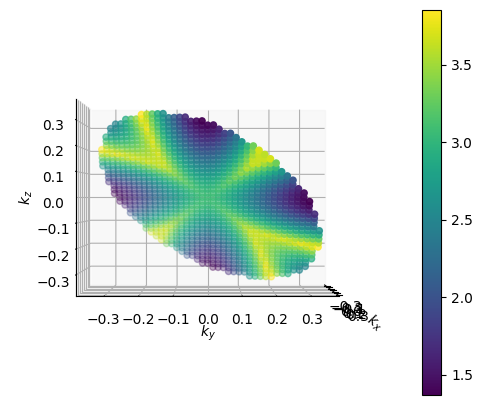

In [331]:
%matplotlib inline 
#inline, widget
# Create a 3D surface plot
import matplotlib.pyplot as plt
fig = plt.figure(figsize=(7,5))
ax = fig.add_subplot(111, projection='3d')
# sc=ax.scatter(kp1.kx, kp1.ky, kp1.kz, c=Hartree_to_eV*band_kz0_sel)
sc=ax.scatter(kp1.kx, kp1.ky, kp1.kz, c=Hartree_to_eV*band_kz0_sel.eigenvalues,  cmap='viridis')
ax.set_xlabel(r'$k_x$')
ax.set_ylabel(r'$k_y$')
ax.set_zlabel(r'$k_z$')
# ax.view_init(elev=90, azim=-90) #1, 1, -1
ax.view_init(elev=0, azim=0) #1, -1, -1
fig.colorbar(sc)
plt.show()

In [332]:
ksplitting_norm=np.sqrt(0.05**2+0.1**2)
print(ksplitting_norm*np.pi/a0)

6637487958.951808


In [333]:
from scipy.constants import e, c, h

In [334]:
(e/h/c)

806554.3937349211

In [335]:
1E4/3200e-9/1E9

3.125

In [336]:
pwd

'/home/thibault.derrien/Documents/octopus.data/03-Bulk3D.mEff/Si-1x1x1-k-60x60x1-Angle0-Mesh0.434637-Mesh0.434637-T0e0-TB09/static'

(11,)
(1123,) (1123,) (11,)


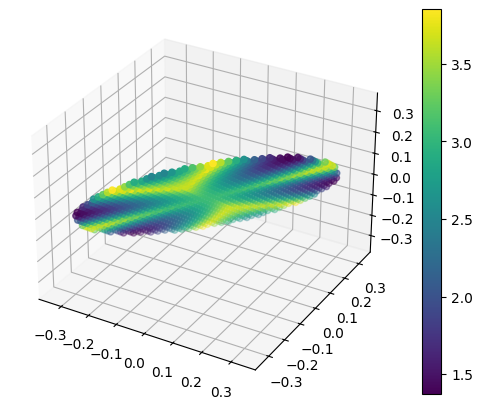

In [337]:
%matplotlib inline
# Create a 3D surface plot
import matplotlib.pyplot as plt
fig = plt.figure(figsize=(7,5))
ax = fig.add_subplot(111, projection='3d')
# X, Y = np.meshgrid(kx, ky)

data_1 = band_kz0_sel*Hartree_to_eV

data_toplot_1 = [item for subarray in data_1 for item in subarray]
print(np.shape(data_toplot_1))
# data_toplot_1 = np.reshape(data_toplot_1, (181,4))
sc = ax.scatter(kp1.kx,kp1.ky,kp1.kz, c=data_1.eigenvalues, cmap='viridis') #WORKS but not perfect
fig.colorbar(sc)

print(np.shape(kp1), np.shape(kp2), np.shape(data_toplot_1))

# surf = ax.plot_surface(kp1.kx, kp1, ky, data_toplot_1, cmap='viridis')
plt.show()
# plt.savefig("Silicon_kxkykzCorrected_Band12.png")


In [257]:
!pwd

/home/thibault.derrien/Documents/octopus.data/03-Bulk3D.mEff/Si-1x1x1-k-50x50x1-Angle0-Mesh0.434637-Mesh0.434637-T0e0-TB09/static


In [258]:
kp1

<xarray.DataArray (k_index: 0)> Size: 0B
array([], dtype=float64)
Coordinates:
  * k_index  (k_index) int64 0B 
    kx       (k_index) float64 0B 
    ky       (k_index) float64 0B 
    kz       (k_index) float64 0B 
    band     int64 8B 4

In [259]:
band_kz0_sel.eigenvalues

<xarray.DataArray 'eigenvalues' (k_index: 0)> Size: 0B
array([], dtype=float64)
Coordinates:
  * k_index  (k_index) int64 0B 
    kx       (k_index) float64 0B 
    ky       (k_index) float64 0B 
    kz       (k_index) float64 0B 
    band     int64 8B 4

## Attempting self described interpolation from ChatGPT

In [93]:
bandstructure_conduction=bandstructure_xarray_corr.sel(band=4) #selecting band number

In [94]:
bandstructure_conduction

<xarray.Dataset> Size: 3MB
Dimensions:      (k_index: 64000)
Coordinates:
  * k_index      (k_index) int64 512kB 0 1 2 3 4 ... 63996 63997 63998 63999
    kx           (k_index) float64 512kB 0.0 0.0167 0.0 -0.0167 ... 0.4 -0.4 0.3
    ky           (k_index) float64 512kB 0.0 0.0 0.0167 ... 0.0333 0.0333 0.2667
    kz           (k_index) float64 512kB 0.0 0.0 0.0 0.0 ... 0.0333 0.1 0.1 0.1
    band         int64 8B 4
Data variables:
    eigenvalues  (k_index) float64 512kB 0.1126 0.1129 ... 0.09771 0.08011

In [95]:
kkx=band_kz0_sel.kx.values
kky=band_kz0_sel.ky.values
kkz=band_kz0_sel.kz.values

In [96]:
kkx = band_kz0_sel['kx'].values
kky = band_kz0_sel['ky'].values
kkz = band_kz0_sel['kz'].values
values = band_kz0_sel.values

In [97]:
import xarray as xr
import numpy as np

# Suppose your original data is like:
# data: (k_index,) shaped
# coords: k_index, kx(k_index), ky(k_index), kz(k_index)

# 1. Extract kx, ky, kz and data values
kx = bandstructure_conduction['kx'].values
ky = bandstructure_conduction['ky'].values
kz = bandstructure_conduction['kz'].values
values = bandstructure_conduction['eigenvalues'].values

# 2. Try to detect unique kx, ky, kz
kx_unique = np.unique(kx)
ky_unique = np.unique(ky)
kz_unique = np.unique(kz)

print(len(kx_unique), len(ky_unique), len(kz_unique))  # Check how many points along each axis

# 3. If possible, reshape
try:
    reshaped_values = values.reshape(len(kx_unique), len(ky_unique), len(kz_unique))

    new_data = xr.DataArray(
        reshaped_values,
        dims=('kx', 'ky', 'kz'),
        coords={'kx': kx_unique, 'ky': ky_unique, 'kz': kz_unique},
        name="new_data"
    )

except ValueError as e:
    print(f"Cannot reshape directly: {e}")
    print("Maybe you need interpolation because the mesh isn't structured.")

49 49 49
Cannot reshape directly: cannot reshape array of size 64000 into shape (49,49,49)
Maybe you need interpolation because the mesh isn't structured.


In [98]:
import numpy as np
# from scipy.interpolate import RegularGridInterpolator

# Assume f_data is defined on a 3D grid

# interpolator = RegularGridInterpolator((kx_unique, ky_unique, kz_unique), bandstructure_conduction.values)

# Define two vectors v1, v2 defining the plane
v1 = np.array([0, 1, 1])  # example
v2 = np.array([1, 0, 1])

# Build the grid (s,t) in plane coordinates
s = np.linspace(-0.5, 0.5, 100)
t = np.linspace(-0.5, 0.5, 100)
S, T = np.meshgrid(s, t, indexing='ij')

# Map (s,t) -> (x,y,z)
plane_points = S[..., None]*v1 + T[..., None]*v2

"""# Interpolate f at these points
plane_shape = plane_points.shape[:-1]
flat_points = plane_points.reshape(-1, 3)
f_on_plane = interpolator(flat_points).reshape(plane_shape)

# Now f_on_plane is your scalar field on the plane"""

'# Interpolate f at these points\nplane_shape = plane_points.shape[:-1]\nflat_points = plane_points.reshape(-1, 3)\nf_on_plane = interpolator(flat_points).reshape(plane_shape)\n\n# Now f_on_plane is your scalar field on the plane'

In [99]:
# We need to filter points such as |kz|>0.5. 

In [100]:
plane_points_match=plane_points[np.abs(plane_points[:,:,2])<=0.5]

In [101]:
plane_points_match

array([[ 0.00505051, -0.5       , -0.49494949],
       [ 0.01515152, -0.5       , -0.48484848],
       [ 0.02525253, -0.5       , -0.47474747],
       ...,
       [-0.02525253,  0.5       ,  0.47474747],
       [-0.01515152,  0.5       ,  0.48484848],
       [-0.00505051,  0.5       ,  0.49494949]])

In [102]:
plane_points_match[0]

array([ 0.00505051, -0.5       , -0.49494949])

In [103]:
#new_data.interp?

In [104]:
new_data.interp(kx=0., ky=-0.5, kz=-0.5, kwargs={"fill_value": "extrapolate"})

NameError: name 'new_data' is not defined

In [90]:
new_data.interp(kx=plane_points_match[0][0], ky=plane_points_match[0][1], kz=plane_points_match[0][2], kwargs={"fill_value": "extrapolate"})

NameError: name 'new_data' is not defined

THIS IS AN AMAZING RESULT, searched for MONTHS. 

In [ ]:
kki_size, kk_dim=np.shape(plane_points_match)

In [ ]:
kx_size, ky_size, kz_size = np.shape(new_data)

In [ ]:
np.shape(plane_points_match)

In [ ]:
# Make a loop on plane_points_match
result=[]
for kki in np.arange(0,kki_size):
    print(kki)
    result.append(new_data.interp(kx=plane_points_match[kki][0], ky=plane_points_match[kki][1], kz=plane_points_match[kki][2], method='quadratic').values)

In [ ]:
"""# We just have to make a loop now. 
result=[]
for kiy in np.arange(0,ky_size):
    for kix in np.arange(0,kx_size):
        #we interpolate for each point of the plane
        print(kix, kiy)
        result.append(new_data.interp(kx=plane_points[kix][kiy][0], ky=plane_points[kix][kiy][1], kz=plane_points[kix][kiy][2], method='linear').values)
        """

In [ ]:
result

In [ ]:
plt.figure()
plt.plot(result)
plt.show()

In [ ]:
result_np_size=np.shape(result)[0]

In [ ]:
def prime_factors(n):
    i = 2
    factors = []
    while i * i <= n:
        if n % i:
            i += 1
        else:
            n //= i
            factors.append(i)
    if n > 1:
        factors.append(n)
    return factors

In [ ]:
prime_factors(result_np_size)

In [ ]:
# How to plot this in 2D???

In [ ]:
# result_np=np.array(result)
result_np=np.reshape(np.array(result),[result_np_size//149, 149])

In [ ]:
np.shape(result_np)

In [ ]:
result_np

In [ ]:
plt.figure()
plt.imshow(result_np)
plt.show()

In [ ]:
# It seems order of elements of somehow lost. 

In [ ]:
dx

In [ ]:
plt.figure()
plt.scatter(kp1.kx, kp1.ky, c=band_kz0_sel.eigenvalues)
plt.show()

In [ ]:
plt.figure()
plt.scatter(kp1.kx, kp1.ky, c=dy.eigenvalues)
plt.show()

In [ ]:
plt.figure

## Renormalization

We may not need this at all, since formula is simpler with Hartree atomic unit system. 

In [ ]:
# print(np.shape(band_kz0))
print(np.shape(data_toplot_1))
print(np.shape(kp1))
print(np.shape(kp2))

In [ ]:
np.shape(data_toplot_1)

Formula of effective mass is given by
$m^{-1}_{x} = \hbar^{-2} \frac{\partial^2 E}{\partial k_x^2}$

We need the effective mass of the band #5. 

After expressing $k_x$ in Hartree atomic units, we obtain

$m^{-1}_{x} = m_e \hbar^{-2} a^{-2} \frac{\partial^2 E}{\partial k_x^2}$, where $E$ is expressed in Hartree. 

In [ ]:
print("Data shapes: energies: ", np.shape(data_toplot_7), ", kx: ", np.shape(kx), ", ky: ", np.shape(ky))

# Build an xarray by hand (obselete)

In [ ]:
Eigenvalues

In [ ]:
len(Eigenvalues)

In [ ]:
list(set(kx_set))

In [ ]:
bandstructure3D_np=np.zeros((kgrid, kgrid, kgrid, 8))

In [ ]:
# test_data = np.random.rand(20, 20, 20, 12)
# np.shape(test_data)

In [ ]:
# Version by Tibo
for kidx in k_index:
    eigenvalues=GetEigenValue(int(kidx), NumberOfBands, filename, verbose=0)
    # print(np.shape(eigenvalues))
    # print(eigenvalues)
    # print(int(kidx))
    print(int(kidx)-1, int(kidx)-1, int(kidx)-1)
    print(kx[int(kidx)-1], ky[int(kidx)-1], kz[int(kidx)-1])
    bandstructure3D_np[kx[int(kidx)-1], ky[int(kidx)-1], kz[int(kidx)-1]]=eigenvalues
    print(str(int(kidx))+"/"+str(len(k_index)))

In [ ]:
np.reshape(block_t)

In [ ]:
# REMINDER
# k_index is block_t[:,0]
# k_x is block_t[:,1]
# k_y is block_t[:,2]
# k_z is block_t[:,3]
for kidx, kvalue in enumerate(block_t):
    print(kidx, kvalue[0])

1501 1502.0
1502 1503.0
1503 1504.0
1504 1505.0
1505 1506.0
1506 1507.0
1507 1508.0
1508 1509.0
1509 1510.0
1510 1511.0
1511 1512.0
1512 1513.0
1513 1514.0
1514 1515.0
1515 1516.0
1516 1517.0
1517 1518.0
1518 1519.0
1519 1520.0
1520 1521.0
1521 1522.0
1522 1523.0
1523 1524.0
1524 1525.0
1525 1526.0
1526 1527.0
1527 1528.0
1528 1529.0
1529 1530.0
1530 1531.0
1531 1532.0
1532 1533.0
1533 1534.0
1534 1535.0
1535 1536.0
1536 1537.0
1537 1538.0
1538 1539.0
1539 1540.0
1540 1541.0
1541 1542.0
1542 1543.0
1543 1544.0
1544 1545.0
1545 1546.0
1546 1547.0
1547 1548.0
1548 1549.0
1549 1550.0
1550 1551.0
1551 1552.0
1552 1553.0
1553 1554.0
1554 1555.0
1555 1556.0
1556 1557.0
1557 1558.0
1558 1559.0
1559 1560.0
1560 1561.0
1561 1562.0
1562 1563.0
1563 1564.0
1564 1565.0
1565 1566.0
1566 1567.0
1567 1568.0
1568 1569.0
1569 1570.0
1570 1571.0
1571 1572.0
1572 1573.0
1573 1574.0
1574 1575.0
1575 1576.0
1576 1577.0
1577 1578.0
1578 1579.0
1579 1580.0
1580 1581.0
1581 1582.0
1582 1583.0
1583 1584.0
1584

2201 2202.0
2202 2203.0
2203 2204.0
2204 2205.0
2205 2206.0
2206 2207.0
2207 2208.0
2208 2209.0
2209 2210.0
2210 2211.0
2211 2212.0
2212 2213.0
2213 2214.0
2214 2215.0
2215 2216.0
2216 2217.0
2217 2218.0
2218 2219.0
2219 2220.0
2220 2221.0
2221 2222.0
2222 2223.0
2223 2224.0
2224 2225.0
2225 2226.0
2226 2227.0
2227 2228.0
2228 2229.0
2229 2230.0
2230 2231.0
2231 2232.0
2232 2233.0
2233 2234.0
2234 2235.0
2235 2236.0
2236 2237.0
2237 2238.0
2238 2239.0
2239 2240.0
2240 2241.0
2241 2242.0
2242 2243.0
2243 2244.0
2244 2245.0
2245 2246.0
2246 2247.0
2247 2248.0
2248 2249.0
2249 2250.0
2250 2251.0
2251 2252.0
2252 2253.0
2253 2254.0
2254 2255.0
2255 2256.0
2256 2257.0
2257 2258.0
2258 2259.0
2259 2260.0
2260 2261.0
2261 2262.0
2262 2263.0
2263 2264.0
2264 2265.0
2265 2266.0
2266 2267.0
2267 2268.0
2268 2269.0
2269 2270.0
2270 2271.0
2271 2272.0
2272 2273.0
2273 2274.0
2274 2275.0
2275 2276.0
2276 2277.0
2277 2278.0
2278 2279.0
2279 2280.0
2280 2281.0
2281 2282.0
2282 2283.0
2283 2284.0
2284

3035 3036.0
3036 3037.0
3037 3038.0
3038 3039.0
3039 3040.0
3040 3041.0
3041 3042.0
3042 3043.0
3043 3044.0
3044 3045.0
3045 3046.0
3046 3047.0
3047 3048.0
3048 3049.0
3049 3050.0
3050 3051.0
3051 3052.0
3052 3053.0
3053 3054.0
3054 3055.0
3055 3056.0
3056 3057.0
3057 3058.0
3058 3059.0
3059 3060.0
3060 3061.0
3061 3062.0
3062 3063.0
3063 3064.0
3064 3065.0
3065 3066.0
3066 3067.0
3067 3068.0
3068 3069.0
3069 3070.0
3070 3071.0
3071 3072.0
3072 3073.0
3073 3074.0
3074 3075.0
3075 3076.0
3076 3077.0
3077 3078.0
3078 3079.0
3079 3080.0
3080 3081.0
3081 3082.0
3082 3083.0
3083 3084.0
3084 3085.0
3085 3086.0
3086 3087.0
3087 3088.0
3088 3089.0
3089 3090.0
3090 3091.0
3091 3092.0
3092 3093.0
3093 3094.0
3094 3095.0
3095 3096.0
3096 3097.0
3097 3098.0
3098 3099.0
3099 3100.0
3100 3101.0
3101 3102.0
3102 3103.0
3103 3104.0
3104 3105.0
3105 3106.0
3106 3107.0
3107 3108.0
3108 3109.0
3109 3110.0
3110 3111.0
3111 3112.0
3112 3113.0
3113 3114.0
3114 3115.0
3115 3116.0
3116 3117.0
3117 3118.0
3118

3732 3733.0
3733 3734.0
3734 3735.0
3735 3736.0
3736 3737.0
3737 3738.0
3738 3739.0
3739 3740.0
3740 3741.0
3741 3742.0
3742 3743.0
3743 3744.0
3744 3745.0
3745 3746.0
3746 3747.0
3747 3748.0
3748 3749.0
3749 3750.0
3750 3751.0
3751 3752.0
3752 3753.0
3753 3754.0
3754 3755.0
3755 3756.0
3756 3757.0
3757 3758.0
3758 3759.0
3759 3760.0
3760 3761.0
3761 3762.0
3762 3763.0
3763 3764.0
3764 3765.0
3765 3766.0
3766 3767.0
3767 3768.0
3768 3769.0
3769 3770.0
3770 3771.0
3771 3772.0
3772 3773.0
3773 3774.0
3774 3775.0
3775 3776.0
3776 3777.0
3777 3778.0
3778 3779.0
3779 3780.0
3780 3781.0
3781 3782.0
3782 3783.0
3783 3784.0
3784 3785.0
3785 3786.0
3786 3787.0
3787 3788.0
3788 3789.0
3789 3790.0
3790 3791.0
3791 3792.0
3792 3793.0
3793 3794.0
3794 3795.0
3795 3796.0
3796 3797.0
3797 3798.0
3798 3799.0
3799 3800.0
3800 3801.0
3801 3802.0
3802 3803.0
3803 3804.0
3804 3805.0
3805 3806.0
3806 3807.0
3807 3808.0
3808 3809.0
3809 3810.0
3810 3811.0
3811 3812.0
3812 3813.0
3813 3814.0
3814 3815.0
3815

In [ ]:
# ChatGPT version
# Initialize the bandstructure3D_np array if it's not already defined
if 'bandstructure3D_np' not in locals():
    bandstructure3D_np = np.zeros((len(kx_set), len(ky_set), len(kz_set), NumberOfBands))

for kidx, kvalue in enumerate(block_t):
    eigenvalues = GetEigenValue(int(kvalue[0]), NumberOfBands, filename, verbose=0)

    # Check if the eigenvalues array has the expected shape
    if eigenvalues.shape[0] != NumberOfBands:
        print(f"Warning: Eigenvalues for kidx={i} do not have the expected shape.")

    kidx_int = int(i) - 1

    for j, kx_val in enumerate(block_t):
        for k, ky_val in enumerate(ky_set):
            for l, kz_val in enumerate(kz_set):
                # Update the bandstructure3D_np array with eigenvalues using indices
                bandstructure3D_np[j, k, l] = eigenvalues[kidx]

    # Print information
    print(f"kidx: {kidx_int}")
    print(f"Processed: {int(i)}/{len(k_index)}")

# Now bandstructure3D_np contains the eigenvalues for all k_index


kidx: 312
Processed: 313/4096
kidx: 313
Processed: 314/4096
kidx: 314
Processed: 315/4096
kidx: 315
Processed: 316/4096
kidx: 316
Processed: 317/4096
kidx: 317
Processed: 318/4096
kidx: 318
Processed: 319/4096
kidx: 319
Processed: 320/4096
kidx: 320
Processed: 321/4096
kidx: 321
Processed: 322/4096
kidx: 322
Processed: 323/4096
kidx: 323
Processed: 324/4096
kidx: 324
Processed: 325/4096
kidx: 325
Processed: 326/4096
kidx: 326
Processed: 327/4096
kidx: 327
Processed: 328/4096
kidx: 328
Processed: 329/4096
kidx: 329
Processed: 330/4096
kidx: 330
Processed: 331/4096
kidx: 331
Processed: 332/4096
kidx: 332
Processed: 333/4096
kidx: 333
Processed: 334/4096
kidx: 334
Processed: 335/4096
kidx: 335
Processed: 336/4096
kidx: 336
Processed: 337/4096
kidx: 337
Processed: 338/4096
kidx: 338
Processed: 339/4096
kidx: 339
Processed: 340/4096
kidx: 340
Processed: 341/4096
kidx: 341
Processed: 342/4096
kidx: 342
Processed: 343/4096
kidx: 343
Processed: 344/4096
kidx: 344
Processed: 345/4096
kidx: 345


kidx: 604
Processed: 605/4096
kidx: 605
Processed: 606/4096
kidx: 606
Processed: 607/4096
kidx: 607
Processed: 608/4096
kidx: 608
Processed: 609/4096
kidx: 609
Processed: 610/4096
kidx: 610
Processed: 611/4096
kidx: 611
Processed: 612/4096
kidx: 612
Processed: 613/4096
kidx: 613
Processed: 614/4096
kidx: 614
Processed: 615/4096
kidx: 615
Processed: 616/4096
kidx: 616
Processed: 617/4096
kidx: 617
Processed: 618/4096
kidx: 618
Processed: 619/4096
kidx: 619
Processed: 620/4096
kidx: 620
Processed: 621/4096
kidx: 621
Processed: 622/4096
kidx: 622
Processed: 623/4096
kidx: 623
Processed: 624/4096
kidx: 624
Processed: 625/4096
kidx: 625
Processed: 626/4096
kidx: 626
Processed: 627/4096
kidx: 627
Processed: 628/4096
kidx: 628
Processed: 629/4096
kidx: 629
Processed: 630/4096
kidx: 630
Processed: 631/4096
kidx: 631
Processed: 632/4096
kidx: 632
Processed: 633/4096
kidx: 633
Processed: 634/4096
kidx: 634
Processed: 635/4096
kidx: 635
Processed: 636/4096
kidx: 636
Processed: 637/4096
kidx: 637


kidx: 888
Processed: 889/4096
kidx: 889
Processed: 890/4096
kidx: 890
Processed: 891/4096
kidx: 891
Processed: 892/4096
kidx: 892
Processed: 893/4096
kidx: 893
Processed: 894/4096
kidx: 894
Processed: 895/4096
kidx: 895
Processed: 896/4096
kidx: 896
Processed: 897/4096
kidx: 897
Processed: 898/4096
kidx: 898
Processed: 899/4096
kidx: 899
Processed: 900/4096
kidx: 900
Processed: 901/4096
kidx: 901
Processed: 902/4096
kidx: 902
Processed: 903/4096
kidx: 903
Processed: 904/4096
kidx: 904
Processed: 905/4096
kidx: 905
Processed: 906/4096
kidx: 906
Processed: 907/4096
kidx: 907
Processed: 908/4096
kidx: 908
Processed: 909/4096
kidx: 909
Processed: 910/4096
kidx: 910
Processed: 911/4096
kidx: 911
Processed: 912/4096
kidx: 912
Processed: 913/4096
kidx: 913
Processed: 914/4096
kidx: 914
Processed: 915/4096
kidx: 915
Processed: 916/4096
kidx: 916
Processed: 917/4096
kidx: 917
Processed: 918/4096
kidx: 918
Processed: 919/4096
kidx: 919
Processed: 920/4096
kidx: 920
Processed: 921/4096
kidx: 921


kidx: 1160
Processed: 1161/4096
kidx: 1161
Processed: 1162/4096
kidx: 1162
Processed: 1163/4096
kidx: 1163
Processed: 1164/4096
kidx: 1164
Processed: 1165/4096
kidx: 1165
Processed: 1166/4096
kidx: 1166
Processed: 1167/4096
kidx: 1167
Processed: 1168/4096
kidx: 1168
Processed: 1169/4096
kidx: 1169
Processed: 1170/4096
kidx: 1170
Processed: 1171/4096
kidx: 1171
Processed: 1172/4096
kidx: 1172
Processed: 1173/4096
kidx: 1173
Processed: 1174/4096
kidx: 1174
Processed: 1175/4096
kidx: 1175
Processed: 1176/4096
kidx: 1176
Processed: 1177/4096
kidx: 1177
Processed: 1178/4096
kidx: 1178
Processed: 1179/4096
kidx: 1179
Processed: 1180/4096
kidx: 1180
Processed: 1181/4096
kidx: 1181
Processed: 1182/4096
kidx: 1182
Processed: 1183/4096
kidx: 1183
Processed: 1184/4096
kidx: 1184
Processed: 1185/4096
kidx: 1185
Processed: 1186/4096
kidx: 1186
Processed: 1187/4096
kidx: 1187
Processed: 1188/4096
kidx: 1188
Processed: 1189/4096
kidx: 1189
Processed: 1190/4096
kidx: 1190
Processed: 1191/4096
kidx: 11

kidx: 1436
Processed: 1437/4096
kidx: 1437
Processed: 1438/4096
kidx: 1438
Processed: 1439/4096
kidx: 1439
Processed: 1440/4096
kidx: 1440
Processed: 1441/4096
kidx: 1441
Processed: 1442/4096
kidx: 1442
Processed: 1443/4096
kidx: 1443
Processed: 1444/4096
kidx: 1444
Processed: 1445/4096
kidx: 1445
Processed: 1446/4096
kidx: 1446
Processed: 1447/4096
kidx: 1447
Processed: 1448/4096
kidx: 1448
Processed: 1449/4096
kidx: 1449
Processed: 1450/4096
kidx: 1450
Processed: 1451/4096
kidx: 1451
Processed: 1452/4096
kidx: 1452
Processed: 1453/4096
kidx: 1453
Processed: 1454/4096
kidx: 1454
Processed: 1455/4096
kidx: 1455
Processed: 1456/4096
kidx: 1456
Processed: 1457/4096
kidx: 1457
Processed: 1458/4096
kidx: 1458
Processed: 1459/4096
kidx: 1459
Processed: 1460/4096
kidx: 1460
Processed: 1461/4096
kidx: 1461
Processed: 1462/4096
kidx: 1462
Processed: 1463/4096
kidx: 1463
Processed: 1464/4096
kidx: 1464
Processed: 1465/4096
kidx: 1465
Processed: 1466/4096
kidx: 1466
Processed: 1467/4096
kidx: 14

...

kidx: 3026
Processed: 3027/4096
kidx: 3027
Processed: 3028/4096
kidx: 3028
Processed: 3029/4096
kidx: 3029
Processed: 3030/4096
kidx: 3030
Processed: 3031/4096
kidx: 3031
Processed: 3032/4096
kidx: 3032
Processed: 3033/4096
kidx: 3033
Processed: 3034/4096
kidx: 3034
Processed: 3035/4096
kidx: 3035
Processed: 3036/4096
kidx: 3036
Processed: 3037/4096
kidx: 3037
Processed: 3038/4096
kidx: 3038
Processed: 3039/4096
kidx: 3039
Processed: 3040/4096
kidx: 3040
Processed: 3041/4096
kidx: 3041
Processed: 3042/4096
kidx: 3042
Processed: 3043/4096
kidx: 3043
Processed: 3044/4096
kidx: 3044
Processed: 3045/4096
kidx: 3045
Processed: 3046/4096
kidx: 3046
Processed: 3047/4096
kidx: 3047
Processed: 3048/4096
kidx: 3048
Processed: 3049/4096
kidx: 3049
Processed: 3050/4096
kidx: 3050
Processed: 3051/4096
kidx: 3051
Processed: 3052/4096
kidx: 3052
Processed: 3053/4096
kidx: 3053
Processed: 3054/4096
kidx: 3054
Processed: 3055/4096
kidx: 3055
Processed: 3056/4096
kidx: 3056
Processed: 3057/4096
kidx: 30

kidx: 3284
Processed: 3285/4096
kidx: 3285
Processed: 3286/4096
kidx: 3286
Processed: 3287/4096
kidx: 3287
Processed: 3288/4096
kidx: 3288
Processed: 3289/4096
kidx: 3289
Processed: 3290/4096
kidx: 3290
Processed: 3291/4096
kidx: 3291
Processed: 3292/4096
kidx: 3292
Processed: 3293/4096
kidx: 3293
Processed: 3294/4096
kidx: 3294
Processed: 3295/4096
kidx: 3295
Processed: 3296/4096
kidx: 3296
Processed: 3297/4096
kidx: 3297
Processed: 3298/4096
kidx: 3298
Processed: 3299/4096
kidx: 3299
Processed: 3300/4096
kidx: 3300
Processed: 3301/4096
kidx: 3301
Processed: 3302/4096
kidx: 3302
Processed: 3303/4096
kidx: 3303
Processed: 3304/4096
kidx: 3304
Processed: 3305/4096
kidx: 3305
Processed: 3306/4096
kidx: 3306
Processed: 3307/4096
kidx: 3307
Processed: 3308/4096
kidx: 3308
Processed: 3309/4096
kidx: 3309
Processed: 3310/4096
kidx: 3310
Processed: 3311/4096
kidx: 3311
Processed: 3312/4096
kidx: 3312
Processed: 3313/4096
kidx: 3313
Processed: 3314/4096
kidx: 3314
Processed: 3315/4096
kidx: 33

kidx: 3551
Processed: 3552/4096
kidx: 3552
Processed: 3553/4096
kidx: 3553
Processed: 3554/4096
kidx: 3554
Processed: 3555/4096
kidx: 3555
Processed: 3556/4096
kidx: 3556
Processed: 3557/4096
kidx: 3557
Processed: 3558/4096
kidx: 3558
Processed: 3559/4096
kidx: 3559
Processed: 3560/4096
kidx: 3560
Processed: 3561/4096
kidx: 3561
Processed: 3562/4096
kidx: 3562
Processed: 3563/4096
kidx: 3563
Processed: 3564/4096
kidx: 3564
Processed: 3565/4096
kidx: 3565
Processed: 3566/4096
kidx: 3566
Processed: 3567/4096
kidx: 3567
Processed: 3568/4096
kidx: 3568
Processed: 3569/4096
kidx: 3569
Processed: 3570/4096
kidx: 3570
Processed: 3571/4096
kidx: 3571
Processed: 3572/4096
kidx: 3572
Processed: 3573/4096
kidx: 3573
Processed: 3574/4096
kidx: 3574
Processed: 3575/4096
kidx: 3575
Processed: 3576/4096
kidx: 3576
Processed: 3577/4096
kidx: 3577
Processed: 3578/4096
kidx: 3578
Processed: 3579/4096
kidx: 3579
Processed: 3580/4096
kidx: 3580
Processed: 3581/4096
kidx: 3581
Processed: 3582/4096
kidx: 35

kidx: 3815
Processed: 3816/4096
kidx: 3816
Processed: 3817/4096
kidx: 3817
Processed: 3818/4096
kidx: 3818
Processed: 3819/4096
kidx: 3819
Processed: 3820/4096
kidx: 3820
Processed: 3821/4096
kidx: 3821
Processed: 3822/4096
kidx: 3822
Processed: 3823/4096
kidx: 3823
Processed: 3824/4096
kidx: 3824
Processed: 3825/4096
kidx: 3825
Processed: 3826/4096
kidx: 3826
Processed: 3827/4096
kidx: 3827
Processed: 3828/4096
kidx: 3828
Processed: 3829/4096
kidx: 3829
Processed: 3830/4096
kidx: 3830
Processed: 3831/4096
kidx: 3831
Processed: 3832/4096
kidx: 3832
Processed: 3833/4096
kidx: 3833
Processed: 3834/4096
kidx: 3834
Processed: 3835/4096
kidx: 3835
Processed: 3836/4096
kidx: 3836
Processed: 3837/4096
kidx: 3837
Processed: 3838/4096
kidx: 3838
Processed: 3839/4096
kidx: 3839
Processed: 3840/4096
kidx: 3840
Processed: 3841/4096
kidx: 3841
Processed: 3842/4096
kidx: 3842
Processed: 3843/4096
kidx: 3843
Processed: 3844/4096
kidx: 3844
Processed: 3845/4096
kidx: 3845
Processed: 3846/4096
kidx: 38

kidx: 4080
Processed: 4081/4096
kidx: 4081
Processed: 4082/4096
kidx: 4082
Processed: 4083/4096
kidx: 4083
Processed: 4084/4096
kidx: 4084
Processed: 4085/4096
kidx: 4085
Processed: 4086/4096
kidx: 4086
Processed: 4087/4096
kidx: 4087
Processed: 4088/4096
kidx: 4088
Processed: 4089/4096
kidx: 4089
Processed: 4090/4096
kidx: 4090
Processed: 4091/4096
kidx: 4091
Processed: 4092/4096
kidx: 4092
Processed: 4093/4096
kidx: 4093
Processed: 4094/4096
kidx: 4094
Processed: 4095/4096
kidx: 4095
Processed: 4096/4096


In [ ]:
bandstructure3D_np

In [ ]:
bandstructure3D_xr=xr.DataArray(bandstructure3D_np, 
                                dims=("kx", "ky", "kz", "energies"),
                                coords={"kx": list(kx_set), "ky": list(ky_set), "kz": list(kz_set)})

In [ ]:
bandstructure3D_xr

In [ ]:
print(bandstructure3D_np[15,15,15])
bandstructure3D_xr[15,15,15]

# Building band structure $E(k_x,k_y,k_z)$ (obselete)

In [ ]:
bandstructure3D=[]
for kidx in k_index:
    eigenvalues=GetEigenValue(int(kidx), NumberOfBands, filename, verbose=0)
    print(np.shape(eigenvalues))
    bandstructure3D.append([k_index[int(kidx)-1], kx[int(kidx)-1], ky[int(kidx)-1], kz[int(kidx)-1], eigenvalues])
    print(str(kidx)+"/"+str(len(k_index)))

(8,)
527.0/4096
(8,)
528.0/4096
(8,)
529.0/4096
(8,)
530.0/4096
(8,)
531.0/4096
(8,)
532.0/4096
(8,)
533.0/4096
(8,)
534.0/4096
(8,)
535.0/4096
(8,)
536.0/4096
(8,)
537.0/4096
(8,)
538.0/4096
(8,)
539.0/4096
(8,)
540.0/4096
(8,)
541.0/4096
(8,)
542.0/4096
(8,)
543.0/4096
(8,)
544.0/4096
(8,)
545.0/4096
(8,)
546.0/4096
(8,)
547.0/4096
(8,)
548.0/4096
(8,)
549.0/4096
(8,)
550.0/4096
(8,)
551.0/4096
(8,)
552.0/4096
(8,)
553.0/4096
(8,)
554.0/4096
(8,)
555.0/4096
(8,)
556.0/4096
(8,)
557.0/4096
(8,)
558.0/4096
(8,)
559.0/4096
(8,)
560.0/4096
(8,)
561.0/4096
(8,)
562.0/4096
(8,)
563.0/4096
(8,)
564.0/4096
(8,)
565.0/4096
(8,)
566.0/4096
(8,)
567.0/4096
(8,)
568.0/4096
(8,)
569.0/4096
(8,)
570.0/4096
(8,)
571.0/4096
(8,)
572.0/4096
(8,)
573.0/4096
(8,)
574.0/4096
(8,)
575.0/4096
(8,)
576.0/4096
(8,)
577.0/4096
(8,)
578.0/4096
(8,)
579.0/4096
(8,)
580.0/4096
(8,)
581.0/4096
(8,)
582.0/4096
(8,)
583.0/4096
(8,)
584.0/4096
(8,)
585.0/4096
(8,)
586.0/4096
(8,)
587.0/4096
(8,)
588.0/4096
(8,)
589

(8,)
1037.0/4096
(8,)
1038.0/4096
(8,)
1039.0/4096
(8,)
1040.0/4096
(8,)
1041.0/4096
(8,)
1042.0/4096
(8,)
1043.0/4096
(8,)
1044.0/4096
(8,)
1045.0/4096
(8,)
1046.0/4096
(8,)
1047.0/4096
(8,)
1048.0/4096
(8,)
1049.0/4096
(8,)
1050.0/4096
(8,)
1051.0/4096
(8,)
1052.0/4096
(8,)
1053.0/4096
(8,)
1054.0/4096
(8,)
1055.0/4096
(8,)
1056.0/4096
(8,)
1057.0/4096
(8,)
1058.0/4096
(8,)
1059.0/4096
(8,)
1060.0/4096
(8,)
1061.0/4096
(8,)
1062.0/4096
(8,)
1063.0/4096
(8,)
1064.0/4096
(8,)
1065.0/4096
(8,)
1066.0/4096
(8,)
1067.0/4096
(8,)
1068.0/4096
(8,)
1069.0/4096
(8,)
1070.0/4096
(8,)
1071.0/4096
(8,)
1072.0/4096
(8,)
1073.0/4096
(8,)
1074.0/4096
(8,)
1075.0/4096
(8,)
1076.0/4096
(8,)
1077.0/4096
(8,)
1078.0/4096
(8,)
1079.0/4096
(8,)
1080.0/4096
(8,)
1081.0/4096
(8,)
1082.0/4096
(8,)
1083.0/4096
(8,)
1084.0/4096
(8,)
1085.0/4096
(8,)
1086.0/4096
(8,)
1087.0/4096
(8,)
1088.0/4096
(8,)
1089.0/4096
(8,)
1090.0/4096
(8,)
1091.0/4096
(8,)
1092.0/4096
(8,)
1093.0/4096
(8,)
1094.0/4096
(8,)
1095.0/40

(8,)
1527.0/4096
(8,)
1528.0/4096
(8,)
1529.0/4096
(8,)
1530.0/4096
(8,)
1531.0/4096
(8,)
1532.0/4096
(8,)
1533.0/4096
(8,)
1534.0/4096
(8,)
1535.0/4096
(8,)
1536.0/4096
(8,)
1537.0/4096
(8,)
1538.0/4096
(8,)
1539.0/4096
(8,)
1540.0/4096
(8,)
1541.0/4096
(8,)
1542.0/4096
(8,)
1543.0/4096
(8,)
1544.0/4096
(8,)
1545.0/4096
(8,)
1546.0/4096
(8,)
1547.0/4096
(8,)
1548.0/4096
(8,)
1549.0/4096
(8,)
1550.0/4096
(8,)
1551.0/4096
(8,)
1552.0/4096
(8,)
1553.0/4096
(8,)
1554.0/4096
(8,)
1555.0/4096
(8,)
1556.0/4096
(8,)
1557.0/4096
(8,)
1558.0/4096
(8,)
1559.0/4096
(8,)
1560.0/4096
(8,)
1561.0/4096
(8,)
1562.0/4096
(8,)
1563.0/4096
(8,)
1564.0/4096
(8,)
1565.0/4096
(8,)
1566.0/4096
(8,)
1567.0/4096
(8,)
1568.0/4096
(8,)
1569.0/4096
(8,)
1570.0/4096
(8,)
1571.0/4096
(8,)
1572.0/4096
(8,)
1573.0/4096
(8,)
1574.0/4096
(8,)
1575.0/4096
(8,)
1576.0/4096
(8,)
1577.0/4096
(8,)
1578.0/4096
(8,)
1579.0/4096
(8,)
1580.0/4096
(8,)
1581.0/4096
(8,)
1582.0/4096
(8,)
1583.0/4096
(8,)
1584.0/4096
(8,)
1585.0/40

(8,)
2018.0/4096
(8,)
2019.0/4096
(8,)
2020.0/4096
(8,)
2021.0/4096
(8,)
2022.0/4096
(8,)
2023.0/4096
(8,)
2024.0/4096
(8,)
2025.0/4096
(8,)
2026.0/4096
(8,)
2027.0/4096
(8,)
2028.0/4096
(8,)
2029.0/4096
(8,)
2030.0/4096
(8,)
2031.0/4096
(8,)
2032.0/4096
(8,)
2033.0/4096
(8,)
2034.0/4096
(8,)
2035.0/4096
(8,)
2036.0/4096
(8,)
2037.0/4096
(8,)
2038.0/4096
(8,)
2039.0/4096
(8,)
2040.0/4096
(8,)
2041.0/4096
(8,)
2042.0/4096
(8,)
2043.0/4096
(8,)
2044.0/4096
(8,)
2045.0/4096
(8,)
2046.0/4096
(8,)
2047.0/4096
(8,)
2048.0/4096
(8,)
2049.0/4096
(8,)
2050.0/4096
(8,)
2051.0/4096
(8,)
2052.0/4096
(8,)
2053.0/4096
(8,)
2054.0/4096
(8,)
2055.0/4096
(8,)
2056.0/4096
(8,)
2057.0/4096
(8,)
2058.0/4096
(8,)
2059.0/4096
(8,)
2060.0/4096
(8,)
2061.0/4096
(8,)
2062.0/4096
(8,)
2063.0/4096
(8,)
2064.0/4096
(8,)
2065.0/4096
(8,)
2066.0/4096
(8,)
2067.0/4096
(8,)
2068.0/4096
(8,)
2069.0/4096
(8,)
2070.0/4096
(8,)
2071.0/4096
(8,)
2072.0/4096
(8,)
2073.0/4096
(8,)
2074.0/4096
(8,)
2075.0/4096
(8,)
2076.0/40

(8,)
2500.0/4096
(8,)
2501.0/4096
(8,)
2502.0/4096
(8,)
2503.0/4096
(8,)
2504.0/4096
(8,)
2505.0/4096
(8,)
2506.0/4096
(8,)
2507.0/4096
(8,)
2508.0/4096
(8,)
2509.0/4096
(8,)
2510.0/4096
(8,)
2511.0/4096
(8,)
2512.0/4096
(8,)
2513.0/4096
(8,)
2514.0/4096
(8,)
2515.0/4096
(8,)
2516.0/4096
(8,)
2517.0/4096
(8,)
2518.0/4096
(8,)
2519.0/4096
(8,)
2520.0/4096
(8,)
2521.0/4096
(8,)
2522.0/4096
(8,)
2523.0/4096
(8,)
2524.0/4096
(8,)
2525.0/4096
(8,)
2526.0/4096
(8,)
2527.0/4096
(8,)
2528.0/4096
(8,)
2529.0/4096
(8,)
2530.0/4096
(8,)
2531.0/4096
(8,)
2532.0/4096
(8,)
2533.0/4096
(8,)
2534.0/4096
(8,)
2535.0/4096
(8,)
2536.0/4096
(8,)
2537.0/4096
(8,)
2538.0/4096
(8,)
2539.0/4096
(8,)
2540.0/4096
(8,)
2541.0/4096
(8,)
2542.0/4096
(8,)
2543.0/4096
(8,)
2544.0/4096
(8,)
2545.0/4096
(8,)
2546.0/4096
(8,)
2547.0/4096
(8,)
2548.0/4096
(8,)
2549.0/4096
(8,)
2550.0/4096
(8,)
2551.0/4096
(8,)
2552.0/4096
(8,)
2553.0/4096
(8,)
2554.0/4096
(8,)
2555.0/4096
(8,)
2556.0/4096
(8,)
2557.0/4096
(8,)
2558.0/40

(8,)
2983.0/4096
(8,)
2984.0/4096
(8,)
2985.0/4096
(8,)
2986.0/4096
(8,)
2987.0/4096
(8,)
2988.0/4096
(8,)
2989.0/4096
(8,)
2990.0/4096
(8,)
2991.0/4096
(8,)
2992.0/4096
(8,)
2993.0/4096
(8,)
2994.0/4096
(8,)
2995.0/4096
(8,)
2996.0/4096
(8,)
2997.0/4096
(8,)
2998.0/4096
(8,)
2999.0/4096
(8,)
3000.0/4096
(8,)
3001.0/4096
(8,)
3002.0/4096
(8,)
3003.0/4096
(8,)
3004.0/4096
(8,)
3005.0/4096
(8,)
3006.0/4096
(8,)
3007.0/4096
(8,)
3008.0/4096
(8,)
3009.0/4096
(8,)
3010.0/4096
(8,)
3011.0/4096
(8,)
3012.0/4096
(8,)
3013.0/4096
(8,)
3014.0/4096
(8,)
3015.0/4096
(8,)
3016.0/4096
(8,)
3017.0/4096
(8,)
3018.0/4096
(8,)
3019.0/4096
(8,)
3020.0/4096
(8,)
3021.0/4096
(8,)
3022.0/4096
(8,)
3023.0/4096
(8,)
3024.0/4096
(8,)
3025.0/4096
(8,)
3026.0/4096
(8,)
3027.0/4096
(8,)
3028.0/4096
(8,)
3029.0/4096
(8,)
3030.0/4096
(8,)
3031.0/4096
(8,)
3032.0/4096
(8,)
3033.0/4096
(8,)
3034.0/4096
(8,)
3035.0/4096
(8,)
3036.0/4096
(8,)
3037.0/4096
(8,)
3038.0/4096
(8,)
3039.0/4096
(8,)
3040.0/4096
(8,)
3041.0/40

(8,)
3466.0/4096
(8,)
3467.0/4096
(8,)
3468.0/4096
(8,)
3469.0/4096
(8,)
3470.0/4096
(8,)
3471.0/4096
(8,)
3472.0/4096
(8,)
3473.0/4096
(8,)
3474.0/4096
(8,)
3475.0/4096
(8,)
3476.0/4096
(8,)
3477.0/4096
(8,)
3478.0/4096
(8,)
3479.0/4096
(8,)
3480.0/4096
(8,)
3481.0/4096
(8,)
3482.0/4096
(8,)
3483.0/4096
(8,)
3484.0/4096
(8,)
3485.0/4096
(8,)
3486.0/4096
(8,)
3487.0/4096
(8,)
3488.0/4096
(8,)
3489.0/4096
(8,)
3490.0/4096
(8,)
3491.0/4096
(8,)
3492.0/4096
(8,)
3493.0/4096
(8,)
3494.0/4096
(8,)
3495.0/4096
(8,)
3496.0/4096
(8,)
3497.0/4096
(8,)
3498.0/4096
(8,)
3499.0/4096
(8,)
3500.0/4096
(8,)
3501.0/4096
(8,)
3502.0/4096
(8,)
3503.0/4096
(8,)
3504.0/4096
(8,)
3505.0/4096
(8,)
3506.0/4096
(8,)
3507.0/4096
(8,)
3508.0/4096
(8,)
3509.0/4096
(8,)
3510.0/4096
(8,)
3511.0/4096
(8,)
3512.0/4096
(8,)
3513.0/4096
(8,)
3514.0/4096
(8,)
3515.0/4096
(8,)
3516.0/4096
(8,)
3517.0/4096
(8,)
3518.0/4096
(8,)
3519.0/4096
(8,)
3520.0/4096
(8,)
3521.0/4096
(8,)
3522.0/4096
(8,)
3523.0/4096
(8,)
3524.0/40

(8,)
3952.0/4096
(8,)
3953.0/4096
(8,)
3954.0/4096
(8,)
3955.0/4096
(8,)
3956.0/4096
(8,)
3957.0/4096
(8,)
3958.0/4096
(8,)
3959.0/4096
(8,)
3960.0/4096
(8,)
3961.0/4096
(8,)
3962.0/4096
(8,)
3963.0/4096
(8,)
3964.0/4096
(8,)
3965.0/4096
(8,)
3966.0/4096
(8,)
3967.0/4096
(8,)
3968.0/4096
(8,)
3969.0/4096
(8,)
3970.0/4096
(8,)
3971.0/4096
(8,)
3972.0/4096
(8,)
3973.0/4096
(8,)
3974.0/4096
(8,)
3975.0/4096
(8,)
3976.0/4096
(8,)
3977.0/4096
(8,)
3978.0/4096
(8,)
3979.0/4096
(8,)
3980.0/4096
(8,)
3981.0/4096
(8,)
3982.0/4096
(8,)
3983.0/4096
(8,)
3984.0/4096
(8,)
3985.0/4096
(8,)
3986.0/4096
(8,)
3987.0/4096
(8,)
3988.0/4096
(8,)
3989.0/4096
(8,)
3990.0/4096
(8,)
3991.0/4096
(8,)
3992.0/4096
(8,)
3993.0/4096
(8,)
3994.0/4096
(8,)
3995.0/4096
(8,)
3996.0/4096
(8,)
3997.0/4096
(8,)
3998.0/4096
(8,)
3999.0/4096
(8,)
4000.0/4096
(8,)
4001.0/4096
(8,)
4002.0/4096
(8,)
4003.0/4096
(8,)
4004.0/4096
(8,)
4005.0/4096
(8,)
4006.0/4096
(8,)
4007.0/4096
(8,)
4008.0/4096
(8,)
4009.0/4096
(8,)
4010.0/40

In [ ]:
np.shape(bandstructure3D)

In [ ]:
bandstructure3D[:][3]

In [ ]:
np.sort(list(kx_set))

# Let's use the object to fill an xarray for interpolation (obselete)

In [ ]:
# Xarray interpolation acording to ChatGPT
# Create example data
kx = np.linspace(0, 10, 20)
ky = np.linspace(0, 10, 20)
kz = np.linspace(0, 10, 20)
data = np.random.rand(20, 20, 20, 12)

# Create an xarray DataArray
da = xr.DataArray(data, dims=("kx", "ky", "kz", "values"), coords={"kx": kx, "ky": ky, "kz": kz})

# Specify the value layer you want to interpolate
value_index = 0  # Change this to the value layer you want to interpolate

# Extract the specific value layer
value_to_interpolate = da.isel(values=value_index)

# Define the new coordinates for interpolation (e.g., finer grid)
new_kx = np.linspace(0, 10, 100)
new_ky = np.linspace(0, 10, 100)
new_kz = np.linspace(0, 10, 100)

# Perform interpolation using xarray's interp method
interpolated_value = value_to_interpolate.interp(kx=new_kx, ky=new_ky, kz=new_kz, method="linear")

# Now, `interpolated_value` contains the independently interpolated values for the specified value layer


In [ ]:
bandstructure3D_xr=xr.DataArray(bandstructure3D)

In [ ]:
bandstructure3D_np=np.transpose(bandstructure3D)[4]

In [ ]:
bandstructure3D_np

In [ ]:
data=bandstructure3D_xr.transpose()[4]

In [ ]:
data.to_series()

In [ ]:
np.sort(list(kx_set))

In [ ]:
bandstructure3D_xr=xr.DataArray(data.to_series(), dims=("kx", "ky", "kz"),
                                coords={"kx": np.sort(list(kx_set)), "ky": np.sort(list(ky_set)), "kz": np.sort(list(kz_set))})

# Exporting to CSV file

In [ ]:
from spp_extended_theory.Libs.libDatabase import ExportToTxt
ExportToTxt(bandstructure3D, "Si-TB09-k16-8unocc-FullBandStructure-NormalizedKPoints.csv")

In [ ]:
!pwd

Final band structure is modified using Kate, to shape it in manner that is plottable by someone. 

In [ ]:
import matplotlib.pyplot as plt

In [ ]:
bandstructure3D

# Exporting to VTK file

Header of the VTK file should contain this. 

In [ ]:
"""#vtk DataFile Version 2.0
kx ky kz then energies for 10 electronic states each
ASCII
DATASET STRUCTURED_POINTS
DIMENSIONS len(kx_set) len(ky_set) len(kz_set)
ORIGIN 0 0 0
SPACING 1./len(kx_set) 1./len(ky_set) 1./len(kz_set)
POINT_DATA len(kx_set)*len(ky_set)*len(kz_set)
FIELD eigenvalue 1
eigenvalues NumberOfBands len(kx_set)*len(ky_set)*len(kz_set) double
"""

We shall try interpolation into a certain plane using Xarray, as well. 

# PyMatGen may enable easy section along a certain path

In [ ]:
# Generated by ChatGPT 3.5
import numpy as np
import matplotlib.pyplot as plt
from pymatgen import Structure
from pymatgen.electronic_structure.bandstructure import BandStructureSymmLine
from pymatgen.electronic_structure.plotter import BSPlotter

# Create a Structure object representing your crystal structure
structure = Structure.from_file('your_structure.cif')

# Define a custom k-path for the section you want
custom_k_path = [[0, 0, 0], [0.5, 0.5, 0.5], [1, 0, 0], [0, 0, 0]]

# Create a BandStructureSymmLine object by interpolating your band structure data along the custom k-path
# Replace 'band_structure_data' with your own data
band_structure = BandStructureSymmLine(structure, custom_k_path, np.array(band_structure_data))

# Create a BSPlotter object for plotting
bs_plotter = BSPlotter(band_structure)

# Plot the band structure along the custom k-path
bs_plotter.get_plot()
plt.show()

# Plotting effective mass as function of radius

In [ ]:
import glob
import numpy as np
import pandas as pd

In [ ]:
filepath="/home/thibault.derrien/Documents/octopus.data/03-Bulk3D"
%cd $filepath

In [ ]:
BandNo=8
filename="*/static/Si-TB09-k16-8unocc-FullBandStructure-NormalizedKPoints-"+str(BandNo)+".csv"

In [ ]:
ListOfFolder=glob.glob(filename)

In [ ]:
ListOfFolder

In [ ]:
plt.figure()

for file in ListOfFolder:
    data_file=np.loadtxt(file, delimiter="\t")
    angles, meff = data_file
    label=file.split("Te")[1].split("eV")[0]
    plt.polar(angles, meff, label=label+" eV")
plt.title(r"$m_{\mathrm{eff}}(\phi)$ for Si[001], band no. "+str(BandNo))
plt.polar(angles, 0*meff, "k--")
plt.ylim([-2,2])
plt.legend(loc=3, ncol=3)
plt.show()
plt.savefig("Si100-110-EffectiveMassSi-Band"+str(BandNo)+"-EffectOfTe.eps")
plt.savefig("Si100-110-EffectiveMassSi-Band"+str(BandNo)+"-EffectOfTe.png")

In [ ]:
!pwd